#### PYTHON LIBRARIES YOU SHOULD KNOW:

1) Numpy: Numerical Computing  
 - NumPy is the foundation for numerical operations in Python.  
 - It provides fast arrays and math functions. 

In [ ]:
import numpy as np

arr = np.array([1,2,3])   # Note that it's already a NumPy array. 
print(arr * 2)

x = [1,3,4]   # Here, note that it's a simple list
arr1 = np.array(x * 2)
print(arr1)

# Point to remember: When we multiply a simply list with 2, the whole list repeated once again inside the list. 
# However, in numpy array each elements got calculated. 

# To repeat the elements of the numpy array, use 'tile' function. 
print(np.tile(arr, 2))

# To repeat each of the elements in numpy array:
print(np.repeat(arr, 2))


[2 4 6]
[1 3 4 1 3 4]
[1 2 3 1 2 3]
[1 1 2 2 3 3]


In [3]:
# Challenge:
# Create a 3X3 matrix of random integers from 1-10

matrix = np.random.randint(1,11, size = (3,3))
print(matrix)

# randint itself does NOT have a random_state parameter

[[ 3  5  7]
 [10 10  6]
 [ 9  1  7]]


##### Let’s do a small, interview-ready experiment that clearly shows **non-reproducible vs reproducible** randomness.


In [4]:
# Experiment 1️⃣ — Without controlling randomness ❌

import numpy as np

num = np.random.randint(0,30,5)
print(num)

# Run this cell multiple times: You’ll get different outputs every time.

# ❌ Problem
   # You cannot reproduce results
   # Debugging becomes difficult
   # Model comparisons become unreliable


[25 12 10 29 17]


In [5]:
# Experiment 2️⃣ — Using np.random.seed() ✅ (old style)

import numpy as np

np.random.seed(42)
num1 = np.random.randint(0,30,5)
print(num1)

# This returns the same values in every run. 
# Here, seed=42 plays the role of random_state
# 42 is commonly sed as a seed due to historical and cultural reasons in computing. 
# Any fixed numbern works; the purpose of a seed is reproducibility, not randomness quality.

[ 6 19 28 14 10]


In [6]:
# Experiment 3️⃣ — Modern & best practice ⭐⭐⭐
   # Using NumPy Generator (random_state equivalent)

import numpy as np

num2 = np.random.default_rng(10)
print(num2.integers(0,10,3))

# integers() replaces randint
# Best practice for ML pipelines & experiments

[7 9 2]


##### 2) Pandas: Data Analysis

Pandas makes it easy to work with tabular data using Dataframes

In [7]:
import pandas as pd

data = {"Name" : ["Alice", "Bob", "Charlie"], "Age" : [24,31,28]}
df = pd.DataFrame(data)
print(df)

      Name  Age
0    Alice   24
1      Bob   31
2  Charlie   28


In [8]:
# “How do you remove index from pandas output?”
    # A DataFrame always has an index. 
    # We usually hide it during display using to_string(index=False) or prevent it from being saved using index=False during export.

# Example: (Print without index)
print(df.to_string(index = False))

   Name  Age
  Alice   24
    Bob   31
Charlie   28


##### 3) Matplotlib: Data Visualization
Matplotlib helps you create charts and plots

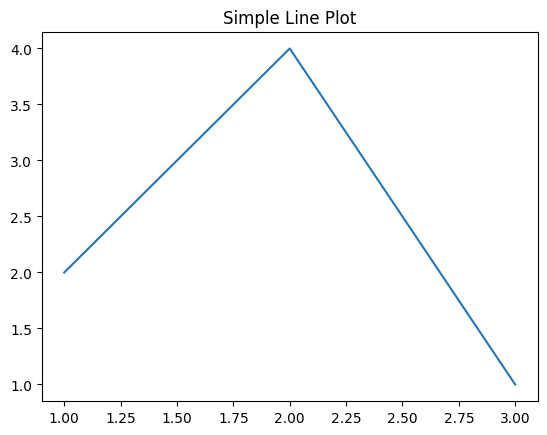

In [9]:
import matplotlib.pyplot as plt

x = [1,2,3]
y = [2,4,1]

plt.plot(x,y)
plt.title("Simple Line Plot")
plt.show()

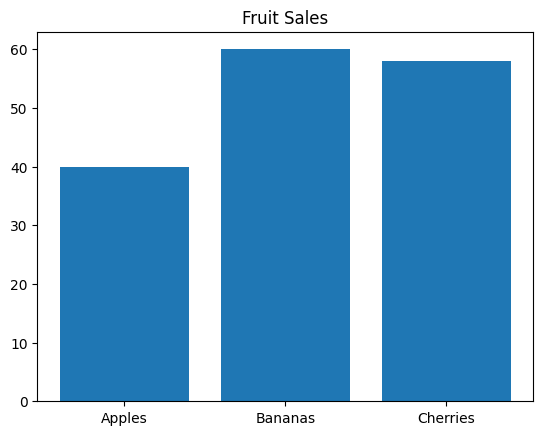

In [10]:
# Challenge: Plot a bar chart of fruit sales. 

fruits = ["Apples", "Bananas" ,"Cherries"]
Sales = [40,60,58]

plt.bar(fruits,Sales)
plt.title("Fruit Sales")
plt.show()

# line chart is default if we use 'plt.plot(x,y)'
# use the type of the chart when use 'plt.plot' to  'plt.bar' if you want to use bar chart. 

##### 4) Seaborn: Statistical Plots

Seaborn builds on  Matplotlib with beautiful, high-level charts.  
Seaborn does come with built-in (default) datasets in Python. You can view those dataset names from the following code.

In [1]:
import seaborn as sns

sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [ ]:
# Example:

import seaborn as sns 

tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


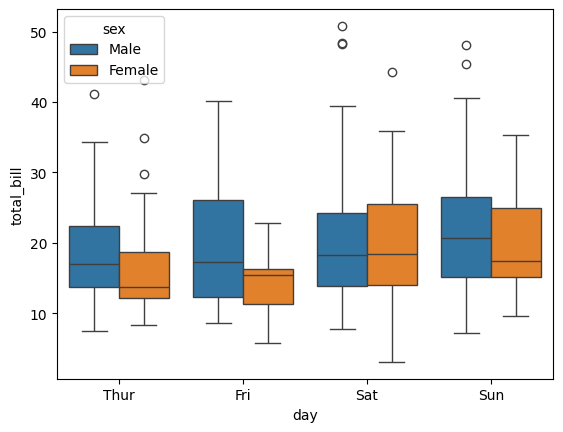

In [ ]:
# Visualization:

import seaborn as sns 
import pandas as pd
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")
sns.boxplot(x="day", y = "total_bill", data = tips, hue = "sex")
plt.show()

# 'hue' adds an extra dimension by coloring data points based on a variable. 

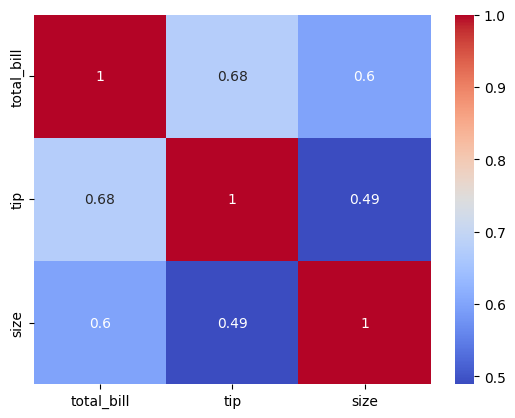

In [ ]:
# Challenge: Create a heatmap of correlation:

# When you write only: corr = tips.corr() -> Pandas tries to convert every column to float, but fails on strings like 'No'.
# Correct & recommended fix (BEST PRACTICE): Explicitly select only numeric columns

corr = tips.select_dtypes(include = "number").corr()
sns.heatmap(corr, annot = True, cmap = "coolwarm")
plt.show()

# annot=True → writes correlation values inside each cell
# cmap="coolwarm" →

    # 🔴 Red → strong positive correlation
    # 🔵 Blue → strong negative correlation
    # ⚪ White → near zero correlation

##### 🎯 Interview-ready explanation

“The error occurs because the dataset contains categorical string values like ‘Yes’ and ‘No’. Correlation requires numeric data, so we must explicitly select numerical columns before computing the correlation matrix.”

##### 5) Requests:  HTTP for Humans

Request makes it easy to send HTTP requests.

🌐 First, what is HTTP?
   - Think of the internet like a big school 🏫
   - You (your computer) want information
   - Another computer (server) has that information.  
To talk to each other, they use a language called HTTP.

Requests is a Python helper 🤝
 - Instead of you speaking complicated computer language,
 - Requests talks nicely to the internet for you.  
Requests does all the hard work behind the scenes 🪄

“Requests: HTTP for Humans” means
👉 A Python tool that lets people talk to websites easily, without pain.



In [ ]:
import requests

response = requests.get("https://api.github.com")
print(response.status_code)   # status_code is a number that tells you what happened.
print(response.json())        # JSON is a neat way to send data.

# You can browse the status code to get the various results.  


200
{'current_user_url': 'https://api.github.com/user', 'current_user_authorizations_html_url': 'https://github.com/settings/connections/applications{/client_id}', 'authorizations_url': 'https://api.github.com/authorizations', 'code_search_url': 'https://api.github.com/search/code?q={query}{&page,per_page,sort,order}', 'commit_search_url': 'https://api.github.com/search/commits?q={query}{&page,per_page,sort,order}', 'emails_url': 'https://api.github.com/user/emails', 'emojis_url': 'https://api.github.com/emojis', 'events_url': 'https://api.github.com/events', 'feeds_url': 'https://api.github.com/feeds', 'followers_url': 'https://api.github.com/user/followers', 'following_url': 'https://api.github.com/user/following{/target}', 'gists_url': 'https://api.github.com/gists{/gist_id}', 'hub_url': 'https://api.github.com/hub', 'issue_search_url': 'https://api.github.com/search/issues?q={query}{&page,per_page,sort,order}', 'issues_url': 'https://api.github.com/issues', 'keys_url': 'https://api

In [ ]:
response2 = requests.get("https://chatgpt.com/c/696c2d61-abd8-8320-a604-513e77204a27")
print(response2.status_code)


403


In [ ]:
# Challenge:
# Fetch and print your IP address. 

res = requests.get("https://api.ipify.org?format=json")
print(res.json())

# https://api.ipify.org is a small helper website.
# Its job is: Tell you your public IP address. Think of IP address like your home address on the internet 🏠🌍

# “From the output, give me only the value called ip”
print(res.json()['ip'])

{'ip': '103.139.34.172'}
103.139.34.172


##### 6) Beautiful Soup: Web Scraping

Beautiful Soup helps you extract data from HTML pages. 

In [ ]:
from bs4 import BeautifulSoup
import requests

url = "https://example.com"
html = requests.get(url).t
ext
soup = BeautifulSoup(html, "html.parser")
print(soup.title.text)

# Step-by-step explanation:

# 1️⃣ from bs4 import BeautifulSoup -> Means: “I want to use BeautifulSoup, a tool that understands web pages.”
# Think of BeautifulSoup as:🕵️‍♂️ A detective who can read messy HTML

# 2️⃣ import requests -> Means: “I want to use requests to talk to websites.”
# Requests is: 📮 A messenger that brings webpage content to Python

# 3️⃣ url = "https://example.com" -> You are saying: “This is the website I want to visit.” 
# Just like writing an address ✉️

# 4️⃣ html = requests.get(url).text
    # a) requests.get(url) -> Python visits the website. The website sends back a reply (using .get)
    # b) .text -> Takes the HTML content of the page. HTML is the skeleton of a webpage

# 5️⃣ soup = BeautifulSoup(html, "html.parser")
   # This means: “Please read this HTML and make it easy to understand.”
       # html → webpage content
       # "html.parser" → tells how to read it

    # Now soup is a structured version of the webpage. Think of it as: 📚 HTML turned into a readable book

# 6️⃣ print(soup.title.text)
    # a) soup.title: Finds the <title> tag in the page
    # b) .text -> Extracts only the words, not HTML tags

Example Domain


#### PYTHON FOR DATA SCIENCE AND MACHINE LEARNING

Python is the most preferred language in the data world because 
- It's easy to read
- Has a huge community & 
- Supports powerful libraries

##### 1) Jupyter Notebook - Your coding playground

Jupyter lets you: 
- Write code in small chunks (cells)
- Mix code, explanations, formulas and plots
- Test & visulize without switching tools

Perfect for experimentaion, data exploration and reporting - used by data scientists every day. 

##### 2) Scikit-learn - Build ML models fast. 

Scikit-learn is a one-stop library for ML tasks:

- Preprocessing: Scaling, Encoding
- Models: Logistic Regression, Random Forest, SVM etc.. 
- Evaluation: Accuracy, Confusion Matrix, etc..
- Pipelines: Chain everything together. 

You can build powerful model sin just a few lines

In [ ]:
# Example: (Don't run cell due to X & y is not defined. Here is just a sample code)

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier()
model.fit(X_train, y_train)

##### 3) Model Training and Evaluation:

Training = Feeding data to the model
Evaluation = Measuring performance on new (unseen) data.

CLASSIFICATION TASKS METRICS:
- Accuracy -> % of correct predictions
- Precision -> % of predicted positives that are correct. 
- Recall -> % of actual postives caught. 
- F1-Score -> balance of precision & recall. 

REGRESSION TASKS METRICS:
- MAE -> Average Error
- MSE/ RMSE -> Penalizes large errors
- R squared -> % of variance explained by the model

In [ ]:
# Example: (Don't run cell. Here is just a sample code)

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

##### Typical ML pipelines:

- Load & explore data : Pandas 
- Clean & preprocess: Handle missing, scale, encode
- Split into train/test: train_test_split
- Model training: Scikit-learn
- Evaluate & improve: Hyperparameters, cross-validation
- Visualize : Matplolib , Seaborn
- Deploy/ Present : Jupyter, APIs, dashboards. 

#### PYTHON FOR AUTOMATION & SCRIPTING

Python is perfect for automating repetitive tasks - saving time and reducing errors. Here's how you can start using it for automation. 

1) Why learn Python for Automation? 
   - Easy syntax, huge community
   - Supports files, emails, APIs, browser automation
   - Cross-platform: works on Windows, Linus, macOS

2) Core concepts you should know:
   - Reading/ writing files
   - using modules (os, shutil, datetime)
   - Error handling with **try-except**
   - Automating via scripts (.py files or cron jobs)

3) File & Folder automation:  (Dec 12, 2025)


### JANUARY 1, 2026

Today, let's start with the first topic in Python programming Roadmap.

1) Python Programming Basics:

Step 1: Install Python & VS code. 
- Download Python 3.11+ from **python.org**
- During install, check ✅ **Add  Python to PATH**
- Install **VS Code**
- In VS Code, install the **Python** extension
- To check: Go to menu 'view' -> 'Terminal' -> Type: **python --version**
- You should see something like: **Python 3.x.x**

👉 The Python extension will NOT install Python for you — it only helps VS Code use Python.

- You can check the further extension by clicking 'Ctrl + shift + X'.

- To check which Python VS Code is using (very important for Data Science):
  - In VS Code: Press Ctrl + Shift + P
  - Type: Python: Select Interpreter
  - Select the interpreter (example) ->  Python 3.12.7
  - Once selected, VS Code connects:  
      👉 Terminal  
      👉 Jupyter  
      👉 Debugger  
      👉 Pandas / NumPy / ML libraries    to that Python version.


#####  PROJECT 1: SIMPLE CALCULATOR

Just try asking two numbers from the user & do the simple calculation code such as addition, subtraction, multiplication & division. 

In [ ]:
number1 = float(input("Enter First Number: "))
number2 = float(input("Enter Second Number: "))

print("Addition: ", number1 + number2)
print("Subtraction: ", number1 - number2)
print("Multiplication: ", number1 * number2)

# Trying bit different, division code using if-else condition:
if number2 != 0:
    print("Division: ", number1 / number2)
else:
    print("Division Not Possible")

Addition:  36.0
Subtraction:  32.0
Multiplication:  68.0
Division:  17.0


##### PROJECT 2: TEMPERATURE CONVERTER (Celsius to Fahrenheit)

Tip: How to convert celsius to fahrenheit?
Simple explanation:
 - Multiply the Celsius value by 9/5
 - Then add 32

In [ ]:
celsius = float(input("Enter temperature in celsius: "))

Fahrenheit = (celsius * 9/5) + 32
print("Temperature in Fahrenheit: ", Fahrenheit)

Temperature in Fahrenheit:  172.4


##### PROJECT 3: AGE AFTER 5 YEARS

In [ ]:
age = int(input("Enter your age: "))

future_age = age + 5
print("Your age after 5 years: ", future_age)

Your age after 5 years:  35


##### PROJECT 4: AREA OF RECTANGLE

Tip: Area of Rectange = length * breadth

In [ ]:
length = float(input("Enter the length: "))
breadth = float(input("Enter the breadth: "))

Area_of_rectange = length * breadth
print("Area of Rectangle: ", Area_of_rectange)

Area of Rectangle:  40


#### PYTHON CONTROL FLOW PART 1 - IF, ELIF, ELSE

What is Control Flow? 
- Your code makes **decisions**
- Runs only when **conditions** are met  
     - Each condition is either **True** or **False**  
     - Python checks from **top to bottom**


##### 1) Basic **if** statement

Check if age is 18 or more. Print "You are eligible to vote"



In [ ]:
age1 = int(input("Enter your age: "))

if age1 >=18:
    print("You are eligible to vote")

# Here, the output returns nothing if you enter the age below 18. 
# Only prints the result when you enter the age is equal to and more than 18. 

You are eligible to vote


##### **if-else** example

Write the code for also **else** condition here for the same example above. 

In [ ]:
age1 = int(input("Enter your age: "))

if age1 >=18:
    print("You are eligible to vote")
else:
    print("You are not eligible to vote")


You are eligible to vote


##### **elif** for multiple conditions. 

Try with student's marks in different Grades using **elif** condition

In [ ]:
marks = int(input("Enter your mark: "))

if marks >= 90:
    print("Grade A")
elif marks >=75:
    print("Grade B")
elif marks >= 50:
    print("Grade C")
else:
    print("Fail")

Grade B


In [ ]:
# Logical Operators

age = 18
has_id = True

if age >= 18 and has_id:
    print("Entry allowed")
else:
    print("Enter denied")

# Both conditions are True -> prints "Entry allowed"

Entry allowed


##### Check is a  year is a leap year

Tip: A leap year can be checked in a few standard ways that are listed below:
- It is divisible by 4
- BUT if it is divisible by 100, it is NOT a leap year
- EXCEPT if it is divisible by 400, then it IS a leap year

In [ ]:
Year = int(input("Enter the year: "))

if (Year % 4 == 0 and Year % 100 !=0) or (Year % 400 == 0):
    print("Yes, It's a Leap Year")
else:
    print("It's not a Leap year")
    

Yes, It's a Leap Year


#### PYTHON CONTROL FLOW PART 2 - FOR loops   (14-01-2026 Wednesday)

What is **for** loops?   
A **for** loop lets you **repeat actions** for each item in a sequence (like a list, string or range)

In [ ]:
# 1. Looping through a list. 
fruits = ["apple", "banana", "cherry"]

for fruit in fruits:
    print(fruit)          # It prints each fruit in the list. 


apple
banana
cherry


In [ ]:
# 2. Using 'range()' to loop numbers

for i in range(5):
    print(i)             # It prints numbers 0 to 4 (5 is not included)

0
1
2
3
4


In [ ]:
# Custom start and end in range():

for i in range(2, 6):
    print(i)

2
3
4
5


In [ ]:
# Using 'range()' with step:

for i in range(1,10,2):
    print(i)            # prints odd numbers from 1 to 9

1
3
5
7
9


In [ ]:
# Looping through a string

for char in "Hii":
    print(char)         # Prints each character in a string

H
i
i


In [ ]:
# Nested For loops. 

for i in range(1, 4):
    for j in range(1, 4):
        print(i, "*", j, "=", i * j)      # Prints a mini multiplication table. 

1 * 1 = 1
1 * 2 = 2
1 * 3 = 3
2 * 1 = 2
2 * 2 = 4
2 * 3 = 6
3 * 1 = 3
3 * 2 = 6
3 * 3 = 9


In [ ]:
# Own task: Create a multiplication table of 5 up until 30. 

n = 5
for i in range(1,7):
    print(n, "*",  i, "=", i * n)
    

5 * 1 = 5
5 * 2 = 10
5 * 3 = 15
5 * 4 = 20
5 * 5 = 25
5 * 6 = 30


##### Common Mistakes:
- Forgetting the colon after **for**
- Misusing **range()** (eg., wrong start/stop/step)
- Non indenting the loop body properly. 

##### Mini Project - Multiples of a given number. 

In [ ]:
num3 = int(input("Enter a number: "))

for i in range(1, 6):
    print(f"{num3} * {i} = {num3 * i}")  # Using f-string. 

9 * 1 = 9
9 * 2 = 18
9 * 3 = 27
9 * 4 = 36
9 * 5 = 45


##### Practise Tasks:
- Print numbers from 1 to 4
- Print even numbers from 2 to 10
- Print each letter in your name
- Print squares of numbers from 1 to 5
- Print all elements in a list of your favourite movie. 

In [ ]:
# 1) Print numbers from 1 to 4

for i in range(1,4):
    print(i)           # range(1, 4) generates numbers from 1 to 3

1
2
3


In [ ]:
# 2) Print even numbers from 2 to 10

for i in range(2,11,2):
    print(i)    # Step of 2 skips odd numbers, starting from 2. 

2
4
6
8
10


In [ ]:
# 3) Print each letter in your name

name = input("Enter your name: ")

for char in name:
    print(char)    # Loops through each character in the string. 

k
r
i
s
h


In [ ]:
# 4) Print squares of numbers from 1 to 5

for i in range(1, 6):
    print(f"Square of {i} is {i **2}")    # i ** 2 calculates the square of each number

Square of 1 is 1
Square of 2 is 4
Square of 3 is 9
Square of 4 is 16
Square of 5 is 25


In [ ]:
# 5) Print all elements in a list of your favourite movie. 

movies = ["Spiderman", "Alice, Wonderland", "Lion King"]

for movie in movies:
    print(movie)    # Replace the list with your own favorite movies!

Spiderman
Alice, Wonderland
Lion King


##### Now, let's move to the next  topic in Python Programming Roadmap.
##### Python Control Flow part - 3: **While** loops 🔁

Basic While loop:

count = 1  
while count <=5:  
    print(count)  
    count = count + 1

##### Key Points. 
- Condition checks before every run
- Update variable inside loop
- Missing update causes infinite loop

##### Common mistake: Infinite loop 

count = 1  
while count <= 5:  
    print(count)  

This never stops. Always make sure to update this variable involved in while loop. 

In [ ]:
## While loop with User Input. 

numbers = int(input("Enter the number: "))

while numbers != 0:
    print("You entered: ", numbers)
    numbers = int(input("Enter the number: "))

You entered:  2


In [ ]:
# 'break statement' - Stops the loop immediately. 

for i in range(1,8):
    if i == 5:
        break
    print(i)   # Note that 5 won't be printed. 

1
2
3
4


##### Use Cases:
- Exit loop on success
- Stop when condition met.

##### Continue statement: Skips current iteration

In [ ]:
for i in range(1,8):
    if i == 6:
        continue
    print(i)

1
2
3
4
5
7


##### Real Example: Number guessing game

In [ ]:
secret = 20

while True:
    guess = int(input("Guess the number between 1 to 20: "))
    
    if guess == secret:
        print("Wonderful! It's correct")
        break
    else:
        print("Try again")

Try again
Try again
Wonderful! It's correct


##### Practise problems for you: 
- Print numbers from 10 to 1 using while
- Keep asking age until valid age above 0
- Sum numbers until user enters 0
- Skip multiples of 5 from 1 to 50
- Stop loop when user enter "exit"

In [ ]:
# 1) Print numbers from 10 to 1 using while

numbers1 = 10

while numbers1 >=1:
    print(numbers1)
    numbers1 = numbers1 - 1


10
9
8
7
6
5
4
3
2
1


In [ ]:
# 2) Keep asking user for age until valid age (above 0)

age = int(input("Enter the age: "))

while age <=0:
    print("Invalid age")
    age = int(input("Enter the age: "))
print("Valid age:", age)

Invalid age
Valid age: 12


In [ ]:
# 3) Sum numbers until user enters 0

total = 0

number3 = int(input("Enter the number: "))

while number3 != 0:
    total = total + number3
    number3 = int(input("Enter the number: "))
    
print("Sum is: ", total)

Sum is:  30


In [ ]:
# 4) Skip multiples of 5 from 1 to 50

num4 = 1

while num4 <= 50:
    if num4 % 5 != 0:
        print(num4)
    num4 += 1


1
2
3
4
6
7
8
9
11
12
13
14
16
17
18
19
21
22
23
24
26
27
28
29
31
32
33
34
36
37
38
39
41
42
43
44
46
47
48
49


In [ ]:
# 5) Stop loop when user enter "exit"

while True:
    text = input("Type Something: ")
    if text == "exit":
        print("Loop stopped")
        break
    print("You typed: ", text)

You typed:  Henry
Loop stopped


##### Tips for you:
- Always update variable in while loop
- Use break to stop loop
- Use continue to skip loop
- Test with small inputs first
- Test wrong inputs
- Fix infinite loops

##### Now, let's move to the next topic in Python Programming Roadmap:

Python Data Structures Part 1: LISTS

- Lists stores multiple values
- It accesses (through indexing) and update data
- Loop through items. 

Key points about Lists:
- Ordered collection
- Allows duplicates 
- Index starts at 0


In [ ]:
numbers2 = [10,20,30,40]

# Add items to a list. 
numbers2.append(50)   # adds at the end
print(numbers2)

numbers2.insert(1, 15)  # adds at specific index
print(numbers2)

# Remove items
numbers2.remove(30)  # remove by value
print(numbers2)

numbers2.pop(0)   # remove  by index
print(numbers2)

numbers2.clear() # clear list    
print(numbers2)


[10, 20, 30, 40, 50]
[10, 15, 20, 30, 40, 50]
[10, 15, 20, 40, 50]
[15, 20, 40, 50]
[]


In [ ]:
# Loop through lists

marks1 = [78, 85, 90,66]

for m in marks1:
    print(m)

length = len(marks1)
print(length)

# Loop with Index:

for i in range(len(marks1)):   # see it as range(4) ~ len(marks1) is 4, isn't it?  Here 'i' refers index values.
    print(i, marks1[i])


78
85
90
66
4
0 78
1 85
2 90
3 66


##### Real example: Student Marks Analysis

Derive the sum and it's average from the below student's mark list. 

In [ ]:
marks2 = [70,85,60,90,75]

total = sum(marks2)
print("Total is: ", total)

# The above one is the most normal method to derive sum. However, try like below to demonstrate youself as bit higher.

total_1 = 0

for m in marks2:
    total_1 = total_1 + m

print("Sum is: ", total_1)
print("Average is: ", total_1/ len(marks2))

Total is:  380
Sum is:  380
Average is:  76.0


##### Common mistakes:
- Using wrong index
- Accessing index out of range
- Forgetting list brackets

##### Practise tasks for you
- Create a list of 5 numbers and print sum
- Find maximum value in a list without using max().
- Count how many marks are above 75
- Replace lowest mark with 0
- Reverse a list using loop (without using reverse() or slicing)

In [ ]:
# 1) Create a list of 5 numbers and print sum

example = [12,15,18,20,22]

total_2 = 0

for n in example:
    total_2 = total_2 + n

print("Sum is: ", total_2)

Sum is:  87


In [ ]:
# 2) Find maximum value in a list without using max().

example = [12,25,18,20,22]

max_value = example[0]  # Initialize max_value; We assume d first element is d maximum initially as starting reference.

for n in example:       # n takes each value in 'example' one by one.
    if n > max_value:   # Compare each value
        max_value = n   # max_value updates only when a bigger number is found

print("Maximum value is: ", max_value)

Maximum value is:  25


In [ ]:
# 3) Count how many marks are above 75

marks2 = [70,85,60,90,75]

count = 0
for m in marks2:
    if m > 75:
        count = count + 1
    
print("Marks above 75 is: ", count)

Marks above 75 is:  2


In [ ]:
# 4) Replace lowest mark with 0

marks2 = [70,85,60,90,75]

min_marks = marks2[0]

for m in  marks2:
    if m < min_marks:
        min_marks = m

index = marks2.index(min_marks)
marks2[index] = 0

print("Updates marks: ", marks2)

# 4b) Replace highest mark with 95

marks2 = [70,85,60,90,75]

maxi_marks = marks2[0]

for m in marks2:
    if m > maxi_marks:
        maxi_marks = m

index1 = marks2.index(maxi_marks)
marks2[index1] = 95

print("Updated marks1: ", marks2)

Updates marks:  [70, 85, 0, 90, 75]
Updated marks1:  [70, 85, 60, 95, 75]


In [ ]:
# 5) Reverse a list using loop (without using reverse() or slicing)

marks2 = [70,85,60,90,75]

reversed_list = []     # Empty list to store result (We create an empty list to collect elements in reverse order)

for i in range(len(marks2)-1, -1, -1):   # Start, Stop, Step. 
    reversed_list.append(marks2[i])      # Loop execution

print("Reversed list: ", reversed_list)

# 📌 Meaning: Start at index 4, Stop before -1, Step -1 (move backwards)

Reversed list:  [75, 90, 60, 85, 70]


##### Now let's move to the next topic in Python programming Roadmap

##### Python Data structures Part 2: Tuples & Sets

1. Tuples:
- Store fixed data
- Protect values from change
- Use faster reads than lists

Key rule: 
- Ordered
- Immutable. No add, remove, update
- Index starts at 0

Where tuples are used:  
- Fixed configuration
- Function returns multiple values
- Data safety

In [ ]:
### Tuple unpacking

a, b, c = (10, 20, 30)
print(a)
print(b)
print(c)

10
20
30


##### 2. Sets

- Store unique values
- Remove duplicates
- Perform set operations

Key rules:  
- Unordered
- No duplicates
- No indexing

In [ ]:
# Add and Remove items:

numbers3 = {10, 20, 30, 40}

numbers3.add(50)
print(numbers3)

numbers3.remove(20)
print(numbers3)

numbers3.discard(100)
print(numbers3)  

# Difference: 'remove' fails if value missing, discard ignores. 

{40, 10, 50, 20, 30}
{40, 10, 50, 30}
{40, 10, 50, 30}


In [ ]:
# Set Operations:
aa = {1,2,3}
bb = {3,4,5}

print(aa | bb)  # Union: Everything from both sets
print(aa & bb)  # Intersection: Only common elements
print(bb - aa)  # Difference: Left set minus right set
print(aa ^ bb)  # Symmetric Difference: Values in one set only

{1, 2, 3, 4, 5}
{3}
{4, 5}
{1, 2, 4, 5}


In [ ]:
# Real Example: Unique visitors count

Visitors = ["A", "B", "A", "C", "B", "D"]

Visitors = set(Visitors)
print("Total Unique Visitors: ", len(Visitors))



Total Unique Visitors:  4


##### Practice tasks for you

- Convert list with duplicates to unique values
- Check if value exists in a set
- Find common elements between two lists
- Use tuple to store data and print nicely
- Swap two variables using tuple

In [ ]:
# 1) Convert list with duplicates to unique values

list_example = [20, 30, 40, 20, 50, 30]    # list with duplicate values
unique_list_example = set(list_example)
print(unique_list_example)


{40, 50, 20, 30}


In [ ]:
# 2) Check if value exists in a set

numbers4 = {13,17,21,29}

value = int(input("Enter the number: "))

if value in numbers4:
    print("Value Exists")
else:
    print("Value doesn't exist")

Value Exists


In [ ]:
# 3) Find common elements between two lists

list1 = [1,2,3,5,6,7]
list2 = [3,5,2,6,8,9]

common = set(list1) & set(list2)
print("Common elements: ", common)


Common elements:  {2, 3, 5, 6}


In [ ]:
# 4) Use tuple to store data and print nicely

date = (22, "January", 2026)

day, month, year = date 
print("Date: ", day, month, year)

Date:  22 January 2026


In [ ]:
# 5) Swap two variables using tuple

exam1 = (16, 23, 36)
exam2 = {28, 17, 18}

exam1, exam2 = exam2, exam1

print("exam1: ", exam1)
print("exam2: ", exam2)

exam1:  {17, 18, 28}
exam2:  (16, 23, 36)


##### Quick remainder:

- Use tuple when data must not change
- Use set to remove duplicates
- Never rely on order in sets. 

##### Let's move to the next topic in Python Programming Roadmap:

Python Data Structures Part-3: Dictionaries

- Store data as key & value
- Fast lookup
- Real world mapping

Key rules:
- Keys are unique
- Values can repeat
- Order is preserved
- Keys are immutable. 

In [ ]:
student = {"name" : "Deepak", "age" : 25, "marks" : 85}

# Access values
print(student["name"])
print(student["age"])

# Safe access:
print(student.get("grade"))
print(student.get("grade", "Not found"))

# Why 'get' is safer? -> No error if key is missing

# Add a new key value: 
student["grade"] = "A" 
print(student)

# Update values:
student["grade"] = "B" 
print(student)

# Delete items:
del student["age"]
print(student)       
student.pop("marks")  

Deepak
25
None
Not found
{'name': 'Deepak', 'age': 25, 'marks': 85, 'grade': 'A'}
{'name': 'Deepak', 'age': 25, 'marks': 85, 'grade': 'B'}
{'name': 'Deepak', 'marks': 85, 'grade': 'B'}


85

In [ ]:
# Loop through dictionary:

# Keys only:

student = {"name" : "Deepak", "age" : 25, "marks" : 85}

for key in student:
    print(key)

# Values only:

for value in student.values():
    print(value)

# Keys and Values:

for key, value in student.items():
    print(key, value)

name
age
marks
Deepak
25
85
name Deepak
age 25
marks 85


In [ ]:
# Check Key existence:

if "age" in student:
    print("Key exists")
else:
    print("Key doesn't exists")

    

if "gender" in student:
    print("Key exists")
else:
    print("Key doesn't exists")

Key exists
Key doesn't exists


In [ ]:
# Check value existence:

if 85 in student.values():
    print("Key exists")

Key exists


In [ ]:
# Real example to find total & average: Student marks record

marks = {"Math": 85, "Science" : 90, "English" : 78}

total = 0

for values in marks.values():
    total = total + values

average = total / len(marks)

print("Total: ", total)
print("Average:", average)


Total:  253
Average: 84.33333333333333


##### Common Mistakes:

- Using list as key
- Accessing missing key directly (without using .get)
- Forgetting key uniqueness

##### Practise tasks for you

- Create a dictionary of 5 products with prices
- Find total price of all products
- Find product with highest price
- Update price of one product
- Remove product

In [ ]:
# 1) Create a dictionary of 5 products with prices

products = {"Apple" : 40, "Banana" : 52, "Cherry" : 30, "Kiwi": 50, "Dragon-fruit": 49}
print(products)

{'Apple': 40, 'Banana': 52, 'Cherry': 30, 'Kiwi': 50, 'Dragon-fruit': 49}


In [ ]:
# 2) Find total price of all products

total_price = 0

for values in products.values():
    total_price = total_price + values

print("Total price: ", total_price)

Total price:  221


In [ ]:
# 3) Find product with highest price  (Here we need to find both product and price)

highest_product = None
highest_price = 0

products = {"Apple" : 40, "Banana" : 52, "Cherry" : 30, "Kiwi": 50, "Dragon-fruit": 78}

for product, price in products.items():
    if price > highest_price:
        highest_product = product
        highest_price = price

print("Highest Product: ", highest_product)
print("Highest Price: ", highest_price)

# (Additional try by own) - Find product with lowest price

lowest_product = None
lowest_price = float('inf')  # Start with infinity for comparison
for product, price in products.items():
    if price < lowest_price:
        lowest_product = product
        lowest_price = price
print("Lowest Product: ", lowest_product)
print("Lowest Price: ", lowest_price)



Highest Product:  Dragon-fruit
Highest Price:  78
Lowest Product:  Cherry
Lowest Price:  30


In [ ]:
# 4) Update price of one product

products["Apple"] = 62
print("Updated Products: ", products)

Updated Products:  {'Apple': 62, 'Banana': 52, 'Cherry': 30, 'Kiwi': 50, 'Dragon-fruit': 78}


In [ ]:
# 5) Remove product

del products["Banana"]

print("After Removal: ", products)

After Removal:  {'Apple': 62, 'Cherry': 30, 'Kiwi': 50, 'Dragon-fruit': 78}


##### Daily rule: 

- Think key value mapping
- Use ".get" for safety
- Loop using items

##### Now, let's build the Student Marks Analyzer using the concepts learnt so far. 

Goal: Analyze marks using lists, loops, conditions, dictionary. 

Problem Statement: 
- Store student marks
- Calculate total and average
- Find highest and lowest marks
- Count pass and fail students. 

Assumptions:
- Pass marks = 40
- Marks out of 100

In [ ]:
# 1) Store the data of student marks

students = {"Amit" : 78, "Deepak": 85, "Ravi" : 35, "Kiran" : 60, "Neha" : 92}
print(students)

{'Amit': 78, 'Deepak': 85, 'Ravi': 35, 'Kiran': 60, 'Neha': 92}


In [ ]:
# 2) Calculate total and average

total_marks1 = 0

for values in students.values():
    total_marks1 = total_marks1 + values

average1 = total_marks1/ len(students)

print("Total marks: ", total_marks1)
print("Average: ", average1)

Total marks:  350
Average:  70.0


In [ ]:
# 3) Find highest and lowest marks along with student name:

students = {"Amit" : 78, "Deepak": 85, "Ravi" : 35, "Kiran" : 60, "Neha" : 92}

highest_marks = 0
student_with_highest_marks = None

lowest_marks = float('inf')  # Start with infinity for comparison
student_with_lowest_marks = None

for value in students.values(): 
    if value > highest_marks:
        highest_marks = value
    if value < lowest_marks:
        lowest_marks = value 
    student_with_highest_marks = max(students, key=students.get)  # Get student with highest marks
    student_with_lowest_marks = min(students, key=students.get)   # Get student with lowest marks

print("Highest_marks: ", highest_marks)
print("Student with highest marks: ", student_with_highest_marks)
print("Lowest marks: ", lowest_marks)
print("Student with lowest marks: ", student_with_lowest_marks)

Highest_marks:  92
Student with highest marks:  Neha
Lowest marks:  35
Student with lowest marks:  Ravi


In [ ]:
# 4) Count pass and fail students. 
pass_count = 0
fail_count = 0

for value in students.values():
    if value >= 40:
        pass_count = pass_count + 1
    else:
        fail_count = fail_count + 1

print("Pass count: ", pass_count)
print("Fail count: ", fail_count)


Pass count:  4
Fail count:  1


##### Sample Output meaning:
- Shows class performance
- Identifies topper and weak student
- Gives pass fail ratio

##### Now, let's move to the next topic in Python programming Roadmap

Python functions - Part 1

What a function is? 
- A block of reusable code
- Runs only when you calls it
- Solves one specific task

Why you need functions
- Avoid repetition
- Improve readability
- Easier debugging

In [ ]:
# Basic function

def greet():
    print("Hello")
greet()

# Function with parameters: 

def greet(name):
    print("Hello", name)
greet("Deepak")

# Function with return value:

def add(a, b):
    return a + b
result = add(10, 5)
print(result)

Hello
Hello Deepak
15


##### Key idea:
- Parameters receive data
- Arguments send data

Important rule:
- 'return' gives output back
- 'print' only shows output



In [ ]:
# Wrong way beginners use: (Don't run this)
def add(a, b):
    print(a + b)   # This cannot be reused in calculations. 

# Correct way:
def add(a, b):
    return a + b

In [ ]:
# Multiple return paths:

def check_pass(marks):
    if marks >= 40:
        return "Pass"
    else:
        return "Fail"
    
check_pass(67)

'Pass'

In [ ]:
# Default parameters:

def power(base, exp = 2):        # 'exp' is a parameter with default value as 2.
    return base ** exp
print(power(5))                  # takes default value as second parameter (that is exp) when no value is mentioned
print(power(5, 3))               # value has been mentioned, so it takes it and ignores the default value. 

25
125


In [ ]:
# Function calling function

def square(n):
    return n*n
def cube(n):
    return square(n) * n
print(square(3))
print(cube(4))

9
64


##### Common mistakes:
- Forgetting return
- Using print instead of return
- Wrong indentation
- Calling function before definition

In [ ]:
# Difference between parameters and arguments with example

def greet(name = "Guest"):   # 'name' is a parameter with default value "Guest"
    print("Hello", name)
greet()              # No argument provided, uses default "Guest"   
greet("Alice")     # Argument "Alice" overrides default parameter


Hello Guest
Hello Alice


##### Mini tasks for you:
- Function to calculate square of a number
- Function to check prime number
- Function to find maximum of two numbers
- Function to calculate simple interest
- Function to count vowels in a string

In [ ]:
# 1) Function to calculate square of a number

def squares(n):
    return n*n
print(square(6))

36


In [ ]:
# 2) Function to check prime number

def is_prime(num):
    if num <= 1:   
        return False    # Means the number should not be negative or equal to 1.
    for i in range(2, int(num**0.5) + 1):  # Only check up to square root of num for efficiency
        if num % i == 0:   # If num is divisible by any number between 2 and its square root, it's not prime
            return False   # Returns False immediately if a divisor is found
    return True            # If no divisors found, it's prime
print(is_prime(17))
print(is_prime(20))

In [ ]:
# 3) Function to find maximum of two numbers

def find_max(a, b):
    if a > b:
        return  a
    else:
        return b
    
print(find_max(20,47))

47

In [ ]:
# 4) Function to calculate simple interest 
# Formula: Simple interest = (Principal * rate * time) / 100

def simple_interest(principal, rate, time):
    return (principal * rate * time) / 100

print(simple_interest(1000, 5, 2))


100.0


In [ ]:
# 5) Function to count vowels in a string

def count_vowels(text):
    vowels = "aeiouAEIOU"
    count = 0
    for char in text:
        if char in vowels:
            count += 1
    return count
    
print(count_vowels("Python Programming"))

4


##### Rule to remember:
- One function, one job
- Name functions clearly. 

##### Now, let's move to the next topic in Python programming Roadmap.

Python functions - Part 2: Modules.

What is a module? 
- A file with Python code
- Helps organize large programs
- Enables code reuse. 

Why modules matter in real industry? 
- Large projects = multiple files
- Teams work on seperate modules
- Cleaner structure

Types of modules:
- Built-in-modules (math, random, datetime, sys)
- User-defined modules (your own.py file)

In [ ]:
# Built-in module examples:

# Math module: 
import math  
print(math.sqrt(25))
print(math.factorial(5))
print(math.pi)

# random module:
import random
print(random.randint(1,100))
print(random.choice([10,20,30,60]))

# datetime module
from datetime import datetime
now = datetime.now()
print(now)

5.0
120
3.141592653589793
13
60
2026-02-24 17:46:15.221092


In [ ]:
# Different import styles:

# 1) Import full  module:
import math
print(math.sqrt(16))

# 2) Import specific function
from math import sqrt
print(sqrt(16))

# 3) Import with alias
import math as m
print(m.sqrt(16))

4.0
4.0
4.0


In [ ]:
# User-defined module (VERY IMPORTANT)

# Step 1: Create a new file in Jupyter notebook(math_utils.py)  
def add(a, b):
    return a + b

def multiply(a, b):
    return a * b

# Step 2: Import and use here in this file

import importlib  
import math_utils

importlib.reload(math_utils)

import math_utils 
print(math_utils.__file__)
print(math_utils.add(10, 5))
print(math_utils.multiply(10, 5))


d:\Python Programming - Whatsapp group\math_utils.py
15
50


##### Practice tasks:
- Import math and print cube root
- Generate random password using random


In [ ]:
# 1) Import math and print cube root

import math

print("Cube root of 8 is: ", math.cbrt(8))

number = 27
cube_root = number ** (1/3)
print("Cube root: ", cube_root)

#(Alternative method using math.pow)
print(math.pow(number, 1/3))



Cube root of 8 is:  2.0
Cube root:  3.0
3.0


In [ ]:
# 2) Generate random password using random (VERY IMPORTANT)

import random
import string

characters = string.ascii_letters + string.digits

password = " " 

for i in range(8):
    password += random.choice(characters)

print("Password: ", password)


Password:   k6iaMW78


##### Now, let's move to the next topic in Python programming Roadmap.

Python Strings and File handling: Part 1

What a string is? 
- Sequence of characters
- Written inside quotes
- Immutable 

Common String methods:
- Upper/ Lower
- Remove spaces
- Replace text
- Split string
- Check content

In [ ]:
data1 = " Good Morning  "
data2 = "apple,banana,cherry"
data3 = "Python123"

print(data1.strip())
print(data1.replace("Morning", "Afternoon"))

print(data2.split(","))

print(data3.isalpha())
print(data3.isdigit())
print(data3.isalnum())


Good Morning
 Good Afternoon  
['apple', 'banana', 'cherry']
False
False
True


In [ ]:
# String formatting:

# Old way:
name = "Deepak"  
Age = 25
print("Name:", name, "Age:", Age)

# New way: f-string (industry standard)
print(f"Name: {name}, Age: {Age}")

Name: Deepak Age: 25
Name: Deepak, Age: 25


In [ ]:
# Loop through string:

word = "Python" 
for char in word:
    print(char)

P
y
t
h
o
n


##### Common Mistakes:
- Treating string as mutable
- Wrong slicing indexes
- Forgetting strings are zero-indexed

##### Practise tasks for you
- Reverse a string
- Count words in a sentence
- Check Palindrome
- Count frequency of each character
- Capitalize first letter of each word. 

In [ ]:
# 1) Reverse a string

word = input("Enter a word: ")
reversed_word = word[::-1]
print(reversed_word)

ykcaJ


In [ ]:
# 2) Count words in a sentence

sentence = "Python is Awesome tool"

words = sentence.split()
print("Words count:", len(words))

Words count: 4


In [ ]:
# 3) Check Palindrome

word1 = input("Enter a word: ")
if word1 == word1[::-1]:
    print("It's palindrome")
else:
    print("It's not Panlindrome")

It's not Panlindrome


In [ ]:
# 4) Count frequency of each character

sentence = "Python is Awesome tool"

freq = {}

for char in sentence:
    if char in freq:
        freq[char] += 1
    else:
        freq[char] = 1
print("Character frequency: ", freq)

Character frequency:  {'P': 1, 'y': 1, 't': 2, 'h': 1, 'o': 4, 'n': 1, ' ': 3, 'i': 1, 's': 2, 'A': 1, 'w': 1, 'e': 2, 'm': 1, 'l': 1}


In [ ]:
# 5) Capitalize first letter of each word.

word2 = "today is tuesday"

capitalized = word2.title()
print(capitalized)

Today Is Tuesday


##### Now, let's move to the next topic in Python Programming Roadmap. 

Python Strings and File handling. Part - 2

What is file handling means? 
- Read data from files
- Write data to files
- Store data permanently. 

Why it matters in real projects
- Logs
- Automation
- Reports
- Data storage



##### Opening a file

Basic syntax: file = open("data.txt", "r")

Modes:
- "r" -> read
- "w" -> write
- "a" -> append
- "r+" -> read + write

In [ ]:
#  READING FROM A FILE

# 1) Read Entire file
file = open("data.txt", "r")
content = file.read()
print(content)
file.close()

# 2) Read line by line
file = open("data.txt", "r")
for line in file:
    print(line.strip())
file.close()

# can we code without using strip() function? 
# Yes, but it will include the newline characters at the end of each line, which may affect the formatting of the output.

# 3) Read one line:
file = open("data.txt", "r")
print(file.readline())
file.close()


Hi user, 
Welcome to Python
Hi user,
Welcome to Python
Hi user, 



In [ ]:
# WRITING TO A FILE:

# Write mode (overwrites file)
file = open("data.txt", "w")
file.write("Hello Python\n")
file.write("File handling is easy")
file.close()

# APPEND MODE:
file = open("data.txt", "a")
file.write("\nNew line added")
file.close()

# Read the file again after appending

file = open("data.txt", "r")
content1 = file.read()   
print(content1)

Hello Python
File handling is easy
New line added


##### Note: 
- After overwriting, how can i read the file?  
   -> You cannot read from a file opened in write mode.   
   -> To read, you need to open the file in read mode ('r') after closing it from write mode.

In [ ]:
# Best practise to handle files using 'with' statement (automatically closes file)

with open("data.txt", "r") as file:
    content = file.read()
    print(content)

Hello Python
File handling is easy
New line added


In [ ]:
# Real example: Student marks file

# Creating a file by write mode
marks = open("marks.txt", "w")
marks.write("Amit 78\n")
marks.write("Deepak 85\n")
marks.write("Ravi 35\n")
marks.close()

# Reading a file by line by line in a read mode by using 'with'. 
with open("marks.txt", "r") as marks:
    for line in marks:
        name, marks = line.split()
        print(name, marks)
# 

Amit 78
Deepak 85
Ravi 35


##### Common Mistakes:
- Forgetting to close file
- Using wrong mode
- Reading file that doesn't exist
- **Overwriting data by mistake**

##### Practise tasks
- Create a file and write 5 names
- Read file and print each line
- Count number of lines in a file
- Append new data to file
- Read marks from file and calculate average. 

In [ ]:
# 1) Create a file and write 5 names

names = open("names.txt", "w")
names.write("Arun\n")
names.write("Bala\n")
names.write("Chaarly\n")
names.write("Deepak\n")
names.write("Elizabeth\n")
names.close()

In [ ]:
# 2) Read file and print each line

with open("names.txt","r") as marks:
    for line in marks:
        print(line.strip())
file.close()

Arun
Bala
Chaarly
Deepak
Elizabeth


In [ ]:
# 3) Count number of lines in a file

count = 0

with open("names.txt", "r") as names:
    for line in names:
        count +=1
print("Total lines: ", count)

Total lines:  5


In [ ]:
# 4) Append new data to file
 
with open("names.txt","a") as names:
    names.write("Fathima\n")
    names.write("Sahana\n")

In [ ]:
# 5) Read marks from file and calculate average.

total = 0
average = 0

with open("marks.txt", "r") as marks:  # 'marks' file included both student's names and their corresponding marks
    for line in marks:
        name, marks = line.split()
        total += int(marks)
        count +=1
average = total/ count
print("Average marks: ", average)


Average marks:  24.75


##### Important remainders
- Files store strings, convert to int when needed
- Always use 'WITH'
- "w"overwrites, "a" appends. 

##### Now let's move to the next topic in Python Programming Roadmap

Python Strings and File Handling. Part - 3

What is a CSV file? (CSV: Comma seperated values). 
- Stores tabular data
- Used in Excel, Databases, Analytics
- Very common in Data Analytics

Example csv file -> students.csv

Name,      Marks  
Amit        78  
Deepak      85  
Ravi        35  
Neha        92  

Why CSV is important? 
Real-world usage
- Sales reports
- Students databases
- Customer data
- Machine learning datasets

Reading CSV file:
Python has built-in csv module. 


First understand one key concept:

⚠️ CSV files do NOT store data types.
Everything inside a CSV is stored as text.

So even if you write 78, it is stored as "78" in the file.  
The integer type is applied when you read the file, not when you write it.


In [ ]:
import csv

data = [
    ["Name", "Marks"],   # headers
    ["Amit" , 78],
    ["Deepak", 85],
    ["Ravi", 35],
    ["Neha", 92]
]

with open("students.csv", "w", newline = "") as students:
    writer = csv.writer(students)
    writer.writerows(data)

# why we write 'newline' here? 
# The 'newline=""' parameter in the open() function is used to prevent the addition of extra blank lines when writing to a CSV file on certain platforms (like Windows).

In [ ]:
#  Step 1: Import module 

import csv

# Step 2: Read csv file

with open("students.csv") as students:
    content2 = csv.reader(students)   # note how to read while the format is in csv
    for row in content2:
        print(f"Name:{row[0]} | Marks: {row[1]}")

# In csv.reader, each 'row' is a list of values corresponding to the columns in that row.
# For example, row[0] gives you the first column (Name) and row[1] gives you the second column (Marks) for that particular row. 
# So, we access columns by indexing the 'row' list.
# In the example, row[0] is the Name and row[1] is the Marks for each student.
# If you want to access columns directly, you can use csv.DictReader which allows you to access columns by header names instead of index.


Name:Name | Marks: Marks
Name:Amit | Marks: 78
Name:Deepak | Marks: 85
Name:Ravi | Marks: 35
Name:Neha | Marks: 92


In [ ]:
# Step 3: Skip header row

with open("students.csv", "r") as students:
    content2 = csv.reader(students)
    next(content2)      # skips header  
    for row in content2:
        name = row[0]    # gives "Amit"
        marks = int(row[1])   # gives 78
        print(f"{name} scored {marks}")

Amit scored 78
Deepak scored 85
Ravi scored 35
Neha scored 92


In [ ]:
# Step 4: Access Individual columns (exclude header here also)

import csv
with open("students.csv", "r") as students:
    content3 = csv.reader(students)
    next(content3)
    for row in content3:
        marks = int(row[1])  # second column is marks
        print(marks)

78
85
35
92


In [ ]:
# Calculate Average marks from CSV

import csv
total = 0
count = 0
with open("students.csv", "r") as students:
    content2 = csv.reader(students)
    next(content2)
    for row in content2:
        total += int(row[1])
        count +=1
        average = total / count
        print("Average marks: ", average)

Average marks:  78.0
Average marks:  81.5
Average marks:  66.0
Average marks:  72.5


In [ ]:
# CSV Dictionary Reader: Better way to handle columns 

import csv

with open("students.csv", "r") as students:
    reader = csv.DictReader(students)
    for row in reader:
        print(row)

{'Name': 'Amit', 'Marks': '78'}
{'Name': 'Deepak', 'Marks': '85'}
{'Name': 'Ravi', 'Marks': '35'}
{'Name': 'Neha', 'Marks': '92'}


##### Common mistakes:
- Forgetting newline = "" while writing
- Not skipping header
- Forgetting type conversion
- Wrong column indexing

##### Practice tasks for you
- Read CSV & print only student names
- Count students who scored above 80
- Write new student data info CSV
- Find highest scorer from CSV
- Convert CSV data into dictionary. 

In [ ]:
# 1) Read CSV & print only student names

import csv

with open("students.csv", "r") as students:
    content3 = csv.reader(students)
    next(content3)
    for row in content3:
        names = row[0]
        print(names)

Amit
Deepak
Ravi
Neha


In [ ]:
# 2) Count students who scored above 80

import csv
count = 0

with open("students.csv", "r") as students:
    content3 = csv.reader(students)
    next(content3)
    for row in content3:
        if int(row[1]) > 80:
            count += 1
        print(f"Students scoring above 80: {count}")

Students scoring above 80: 0
Students scoring above 80: 1
Students scoring above 80: 1
Students scoring above 80: 2


In [ ]:
# 3) Write new student data info CSV

import csv

# Write data
with open("students.csv", "a", newline = "") as students:
    writer1 = csv.writer(students)
    writer1.writerow(["Suman", 75])

# Read data 
with open("students.csv", "r") as students:
    reader1 = csv.reader(students)
    next(reader1)
    for row in reader1:
        names = row[0]
        marks = int(row[1])
        print(names, marks)

Amit 78
Deepak 85
Ravi 35
Neha 92
Suman 75


In [ ]:
# 4) Find highest scorer from CSV

import csv
highest_score = 0
topper = ""

with open("students.csv", "r") as students:
    reader1 = csv.reader(students)
    next(reader1)
    for row in reader1:
        name = row[0]
        marks = int(row[1])

        if marks > highest_score:
            highest_score = marks
            topper = name
print("Highest marks: ", highest_score)
print("Topper: ", topper)

Highest marks:  92
Topper:  Neha


In [ ]:
# 5) Convert CSV data into dictionary. 

import csv

with open("students.csv", "r") as students:
    reader2 = csv.DictReader(students)
    for row in reader2:
        row["Marks"] = int(row["Marks"])   # This line shows marks values as integers. 
        print(row)

{'Name': 'Amit', 'Marks': 78}
{'Name': 'Deepak', 'Marks': 85}
{'Name': 'Ravi', 'Marks': 35}
{'Name': 'Neha', 'Marks': 92}
{'Name': 'Suman', 'Marks': 75}


##### Key Remainders:
- CSV values are strings - convert types
- DictReader is cleaner & safer
- Use newline ="" when writing
- Always skip header (DictReader does automatically)

#### Now, let's build the Log file Analyzer using the concepts learnt so far. 

##### Log File Analyzer

Problem statement:

You have a log file like this -> server.log

INFO User login successful  
ERROR Database connection failed  
WARNING Disk space low  
INFO File uploaded  
ERROR Timeout occured  
INFO User Logout.   

You need to:
- Count total lines
- Count INFO, ERROR, WARNING
- Print all ERROR messages
- Save summary into new file

In [ ]:
# Create a 'server.log' file

log_data = [
    "INFO User login successful",   
    "ERROR Database connection failed",   
    "WARNING Disk space low",   
    "INFO File uploaded",   
    "ERROR Timeout occured",   
    "INFO User Logout" 
]

# write data
with open("server.log", "w") as serverlog:
    for row in log_data:
        serverlog.write(row + "\n")

# Read data:
with open("server.log","r") as serverlog:
    for row in serverlog:
        print(row.strip())

# Note that 'write()' only accepts a string, but log_data is a list.
# Also, You cannot iterate over a file opened in "w" mode
    


INFO User login successful
ERROR Database connection failed
WARNING Disk space low
INFO File uploaded
ERROR Timeout occured
INFO User Logout


In [ ]:
# Step 1: Count total lines

count = 0

with open("server.log","r") as serverlog:
    reader4 = serverlog.readlines()
    for row in reader4:
        count +=1
print("Total lines: ", count)


Total lines:  6


In [ ]:
# Step 2: Count INFO, ERROR, WARNING

info_count = 0
error_count = 0
warning_count = 0

with open("server.log","r") as serverlog:
    reader5 = serverlog.readlines()
    for row in reader5:
        if "INFO" in row:
            info_count += 1
        elif "ERROR" in row:
            error_count += 1
        elif "WARNING" in row:
            warning_count += 1
print("Count of INFO lines: ", info_count)
print("Count of ERROR lines: ", error_count)
print("Count of WARNING lines: ", warning_count)



Count of INFO lines:  3
Count of ERROR lines:  2
Count of WARNING lines:  1


In [ ]:
# Step 3: Print all ERROR messages

error = []

with open("server.log","r") as serverlog:
    reader5 = serverlog.readlines()
    for row in reader5:
        if "ERROR" in row:
            print(row.strip())

ERROR Database connection failed
ERROR Timeout occured


In [ ]:
# Step 4: Save summary into new file

# Write Summary
with open("log_summary.txt", "w") as logSummary:
    logSummary.write(f"Total logs: {count} \n")
    logSummary.write(f"INFO logs: {info_count}\n")
    logSummary.write(f"ERROR logs: {error_count}\n")
    logSummary.write(f"WARNING logs: {warning_count}\n")

# Read Summary
with open("log_summary.txt", "r") as logSummary:
    reader6 = logSummary.readlines()
    for row in reader6:
        print(row.strip())

Total logs: 6
INFO logs: 3
ERROR logs: 2
WARNING logs: 1


##### What you learned
- File reading
- Looping
- String searching
- Lists
- Writing files
- Real automation logic

##### Upgrade Challenge
Try adding:
- Count unique error messages
- Handle case-insensitive logs
- Accept filename as input
- Add try-except for file not found

In [ ]:
# 1) Count unique error messages

# The below prints -> counts all ERROR occurrences, not unique errors.

count = 0

with open ("server.log","r") as serverlog:
    for row in serverlog:
        if "ERROR" in row:
            count += 1
print("Total Error Logs: ", count)

# If you want unique ERROR messages
   # count = 0 alone is not enough, because duplicates must be removed.
   # You need something like a list or set to track what you've already seen.



Total Error Logs:  2


In [ ]:
# 2) Handle case-insensitive error logs by counting it: 


            



In [ ]:
# 3) Accept filename as input



In [ ]:
# 4) Add try-except for file not found



#### Now, let's move on to the next topic in the Python Programming Roadmap

Error Handling and Debugging - Part 1

##### An error stops program exection. 

**Example:**

num5 = int(input("Enter a number: "))  
print(10/ num)  

if user enters 0 -> program crashes  
Error handling prevents crashes. 

**try and except (Basic sturcture)**

try:  
risky_code  
except:  
handle_error  

**Example:**

try:  
num5 = int(input("Enter a number: "))  
print(10/ num)  
except:  
print("Something went wrong")  

program doesn not crash.

In [ ]:
# Handling specific errors (important) -> Better practice is to catch exact errors. 

# ZERO DIVISION ERROR

try:
    print(10/0)
except ZeroDivisionError:
    print("Cannot divided by Zero")


Cannot divided by Zero


In [ ]:
# VALUE ERROR:
try:
    num5 = int(input("Enter a number: "))
except ValueError:
    print("Invalid Input")


Invalid Input


In [ ]:
# MULTIPLE EXCEPTIONS
try:
    num5 = int(input("Enter a number"))
    print(10/num5)
except ZeroDivisionError:
    print("Cannot divided by Zero")
except ValueError:
    print("Invalid Input")

Invalid Input


In [ ]:
# Exception as Variable (see real error)
try:
    print(10/0)
except Exception as e:  
    print("Error: ", e)

# Used in real projects

# Here what is mean by Exception?
# In Python, an "Exception" is an error that occurs during the execution of a program. 
# When an error occurs, Python raises an exception, which can be caught and handled using try-except blocks. 
# The "Exception" class is the base class for all built-in exceptions in Python. 
# And it can be used to catch any type of exception. 
# By using "except Exception as e",we can catch any exception that occurs & access d error message through d variable "e". 
# This allows you to handle errors gracefully and provide feedback to the user or log the error for debugging purposes.

Error:  division by zero


In [ ]:
# FINALLY BLOCK (ALWAYS RUNS): Runs whether error occurs or not

try:
    print("Opening file")
except:
    print("Error occured")
finally:
    print("Program finished")

# Use cases:  a) Close files    b) Release resources


Opening file
Program finished


In [ ]:
# ELSE BLOCK (runs if no error)

try:
    num5 = int(input("Enter a number: "))
    print(10/num5)
except:
    print("Error Occured")
else:
    print("You entered: ",  num5)

# Flow order:  try -> except -> else -> finally

Error Occured


In [ ]:
# Example: Safe Calculator

try:
    aaa = int(input("Enter a number: "))
    bbb = int(input("Enter a number: "))
    print("Result: ", aaa/bbb)
except ValueError:
    print("Enter a valid input")
except ZeroDivisionError:
    print("Value cannot be divided by Zero")

Enter a valid input


##### Common Mistakes
- Using bare except everywhere
- Ignoring real errors
- Catching wrong exceptions
- Not testing the error cases. 

##### Practice tasks for you:
- a) Handly division by zero
- b) Handle invalid number input
- c) Open file safely with error handling
- d) Safe list index access
- e) Program that keeps asking until valid input

In [ ]:
# a) Handly division by zero

try:
    num6 = int(input("Enter a number: "))
    result = 10/ num6
    print("Result: ", result)
except ZeroDivisionError:
    print("Number cannot be divided by Zero")

Number cannot be divided by Zero


In [ ]:
# b) Handle invalid number input

try:
    num6 = int(input("Enter a number: "))
    print("You entered: ", num6)
except ValueError:
    print("Try again! Invalid input")


Try again! Invalid input


In [ ]:
# c) Open file safely with error handling

try:
    with open("text.txt", "r") as data:
        content4 = data.read()
        print(content4)
except FileNotFoundError:
    print("There is no such a file name / directory")

There is no such a file name / directory


In [ ]:
# d) Safe list index access

numbers5 = [10,12,14,16]

try:
    index = int(input("Enter index: "))
    print(numbers5[index])
except IndexError:
    print("Index is out of range")
except ValueError:
    print("Enter valid index number")

Index is out of range


In [ ]:
# e) Program that keeps asking until valid input

while True:
    try:
         num6 = int(input("Enter a number: "))
         print("Valid number entered: ", num6)
         break  # Exit loop if input is valid
    except ValueError:
        print("Invalid input, Try again")

# If we did not put 'break' statement there, loop continues even it's true. 

Valid number entered:  12


##### Now, let's move to the next topic in Python Programming Roadmap

✅ Error handling and Debugging - Part 2

📝 Debugging Techniques 🕵️

What is Debugging?  
Debugging = Finding and fixing errors (bugs) in code.  

Types of errors you must know:

- Syntax errors: Wrong code structure
- Runtime errors: Crash during execution
- Logical errors: Wrong output, no crash

1) Syntax Errors (Easy to fix) -> Happens when Python cannot understand the code. 
Example:  
print("Hello"  
Error -> missing bracket  
Fix -> follow correct syntax

👉 Python shows line number automatically

2) Runtime Errors -> Program runs but crashes.  
Example:  
num = int('abc')  
Error -> ValueError  
Fix -> Use try-except

3) Logical Errors (Most dangerous) -> Program runs but gives wrong result.  
Example:  
a = 10;  b = 5  
print(a - b) # wanted addition actually  
No crash -> wrong logic 

##### Most Important Debugging Techniques:

**Technique 1:** Print Debugging (Most used)
Check (Write) Variable values (while printing)  
a = 10
b = 20
print("a: ", a)
print("b: ", b)
print( a + b)
Use to track program flow

**Technique 2:** Check Step-by-step execution: Break big problem into small steps. 

**Bad approach** 
result = ( a + b) * c/ d

**Better Debugging**
sum_value = a + b
print(sum_value)
mul_value = sum_value * c
print(mul_value)

**Technique 3:** Use Python Debugger (pdb) -> Professional debugging tool  
import pdb  
a = 10  
b = 20
pdb.set_trace()  # Used to set a breakpoint and inspect variables  
print( a + b )

pdb.set_trace() is used to pause the execution of a Python program and start the debugger so you can inspect what is happening inside your code step-by-step.

**Technique 4:** Read Error Messages Carefully  
Python error tells:  Line number, Error Type & Reason     
Example: *ZeroDivisionError* -> Division by zero. Always read bottom line first. 

**Technique 5:** Comment out code -> Remove parts to find problem.   
print(a/ 0)  
print("Check working")

**Technique 6:** Test with Edge cases  (Test unusual inputs )   
- 0
- Empty input
- Negative numbers
- Large values  

One of the Example below: 


In [ ]:
numbers6 = []
print(len(numbers6))


0


##### Real Debugging Example below: 

numbers7 = [1,2,3]   
print(numbers7[3])              # Error showing that 'Index is out of range'. 

Debug Steps:
- Check list size
- Print length
- Fix index

##### Common Beginners Mistake

- Ignoring Error messages
- Not testing edge cases
- Debugging whole code at once
- Guessing instead of checking  

##### Practice tasks for you  
- 1) Debug code that divides by Zero
- 2) Fix index error in the list
- 3) Find logical error in average calculation
- 4) Use print debugging to track loop
- 5) Use pdb to inspect variables. 


In [ ]:
# 1) Debug code that divides by Zero

# ❌ Example - Buggy Code:

     # num7 = 0
     # print(10/ num7)

# ✅ Fixed Code:

num8 = int(input("Enter a number: "))
if num8 != 0:
    print(10/ num8)   # Here, 10 is a given number. 
else:
    print("Enter a number other than Zero")


Enter a number other than Zero


In [ ]:
# (Alternative Method - Try Except)

try:
    num8 = int(input("Enter a number: "))
    print(10/ num8)
except ZeroDivisionError:
    print("Cannot divided by Zero")

Cannot divided by Zero


In [ ]:
# 2) Fix index error in the list

numbers7 = [1,2,3] 

# ❌ Example - Buggy Code:
     # print(numbers7[3])

# ✅ Fixed code:

index = int(input("Enter an index value: "))

if index < len(numbers7):
        print(numbers7[index])
else:
    print("Index is out of range")            

Index is out of range


In [ ]:
# 3) Find logical error in average calculation

# ❌ Example - Buggy Code:

numbers7 = [1,2,3] 
sum_val = sum(numbers7)
# print(average)    # Forgot to divide by count

# ✅ Fixed code:
average = sum_val / len(numbers7)    
print("Average: ", average)

Average:  2.0


In [ ]:
# 4) Use print debugging to track loop

numbers7 = [1,2,3] 
total = 0

for n in numbers7:
    print("Current number: ", n)
    total += n
    print("Running total: ", total)
    print("Final total: ", total)

# Purpose -> See step-by-step execution
    

Current number:  1
Running total:  1
Final total:  1
Current number:  2
Running total:  3
Final total:  3
Current number:  3
Running total:  6
Final total:  6


In [ ]:
# 5) Use pdb to inspect variables. 

import pdb
a1 = 10
b1 = 5

pdb.set_trace()

result = a1 + b1
print(result)

# What happens? 
 # - Program pauses
 # - You can check values of a1, b1
 # - Step through execution

##### Useful commands inside debugger
- n -> Executes the next line of code (and stays inside the debugger) and pauses again.
- p variable -> print the value of variable
- c -> continues execution until the next breakpoint or end of program.

Onelone Debugging Rules:
- Always read error messages first, don't panic
- Print values to understand flow
- Test step by step
- Fix cause, not symptoms.

#####  Now, let's move to the next topic in Python programming Roadmap

Error Handling and Debugging - Part 3

📝 Fixing Broken Programs ✅ (This is very important for interviews and real jobs)

What is "Fix the Bug" type problem? 
You are given broken code. There you must, 
- Find the error
- Understand why?
- Fix it. 
(Companies test problem solving this way)

Example 1: Division Bug

❌ Broken Code: 

a11 = 10   
b11 = 0  
print(a1/b11)    -> Problem here is division by zero. 

In [ ]:
# ✅ Fixed code below: 

a11 = 10
b11 = 0

if b11 != 0:
    print (a11/ b11)
else:
    print("Cannot divided by Zero")

In [ ]:
# Example 2: List-index Bug

# ❌ Broken Code: 
   # numbers7 = [1,2,3]
   # print(numbers7[3])   Problem -> Index out of range 


In [ ]:
# ✅ Fixed code below: 

numbers7 = [1,2,3]
index3 = 6

if len(numbers7) > index3:  
    print(numbers7[index3])
else:
    print("Index is out of range")

# Better fix:

print(numbers7[-1])


Index is out of range
3


In [ ]:
# Example 3: Wrong Average Calculations (Logical Error)

# ❌ Broken Code: 
    # marks3 = [70, 80, 90]
    # avg = sum(marks3)
    # print(avg)    -> Problem: Forgot division

# ✅ Fixed code:

marks3 = [70, 80, 90]
total1 = sum(marks3)
average = total1/ len(marks3)    
print("Average: ", average)

Average:  80.0


In [ ]:
# Example 4: Infinite Loop Bug

# ❌ Broken Code: 
   # count = 1
   # while count <= 5:
   # print(count)    -> Problem: Variable never updated. 

# ✅ Fixed code:

count = 1
while count <= 5:
    print(count)
    count += 1

1
2
3
4
5


In [ ]:
# Example 5: Function Return Bug

# ❌ Broken Code: 
   # def add(a11, b11):
   # print(a11 + b11)
   # result = add(10, 0) + 5   -> Problem: Function returns None.

# ✅ Fixed code:

def add(a11, b11):
    return a11 + b11

result = add(11, 4) + 5
print(result)


20


##### Real Interview Strategy:

⭐ When fixing code:
- Read Error message carefully
- Identify error type
- Check variables and inputs
- Test small parts
- Fix root cause

Never Guess

Common Bugs Interviewers Test:
- Off-by-one Errors
- Missing return statement (in def funtions)
- Wrong loop condition
- Index errors
- Division by zero
- Wrong variable usage

##### Practice tasks for you
- Fix program that crashes when list is empty
- Fix function returning wrong value
- Fix loop printing wrong numbers
- Fix file open error if file missing
- Fix string index error

In [ ]:
# 1) Fix program that crashes when list is empty

sample_list = []

# ❌ Problem -> accessing element from empty list

# ✅ Fixed code:

if len(sample_list) > 0:
    print(sample_list[2])
else:
    print("List is empty")


List is empty


In [ ]:
# 2) Fix function returning wrong value

# ❌ Broken Code:
   # def square(n):
   # print(n * n)  -> Problem: returns none

# ✅ Fixed code:

def square(n):
    return (n * n)

result1 = square(4)
print(result1)

16


In [ ]:
# 3) Fix loop printing wrong numbers

# ❌ Broken Code:
   # for i in range(1,5):
   # print(i)    -> Problem: Does not include 5

# ✅ Fixed code:

for i in range(1,6):
    print(i)

1
2
3
4
5


In [ ]:
# 4) Fix file open error if file missing

# ❌ Problem -> Program crashes if file not found. 

# ✅ Fixed code:
try:
    with open("output.txt", "r") as output:
        content5 = output.read()
        print(content5)
except FileNotFoundError:
    print("File doesn't exist")


Hey there, Whatsupp



In [ ]:
# 5) Fix string index error

sample = "Friday"
index2 = 8

# ❌ Broken Code: 
    # print(sample[7])

# ✅ Fixed code:

if len(sample) > index2:
    print(sample[index2])
else:
    print("Index is out of range")

Index is out of range


##### One-line Memory rule: 

Debugging = Observe -> Understand -> Fix

##### Now, let's move to the next topic in Python Programming Roadmap:

✅ Object-Oriented Programming (OOP)   
Part 1: Classes & Objects 🚀

What is Object-Oriented Programming (OOP)?  
OOP : Organizing code using objects and classes. 

Real-world idea:
- Car -> Object
- Student -> object
- Bank account -> object

Each object has:
- Data (attributes)  
- Actions (methods)

What is a class?  -> Blueprint/ template to create objects  
Example: Class = Student, Object = actual student

In [ ]:
# Create a Class:

class Student:
    pass     # Class created. No data yet. 

# Create an Object:
s1 = Student()   # Object = instance of class
print(s1)   

# Attributes (Variables inside class)
class Student:
    name = "Mayur"
    age = 26

s1 = Student()
print(s1.name)
print(s1.age)   # But this is not practical. We use Constructor. 

# Constructor init() -> Runs automatically when object is created. 

class Student:
    def __init__(self, name, age):
        self.name = name
        self.age = age

s1 = Student("Mayur", 26)
s2 = Student("Amit", 25)
print(s2.name)
print(s2.age)

# Key idea: 
# 'self' refers to current object
# Stores object data

# Methods (Functions inside class)

class Student:
    def __init__(self, name):
        self.name = name
    
    def greet(self):
        print("Hello, I am", self.name)

s1 = Student("Priyash")
s1.greet()

Mayur
26
Amit
25
Hello, I am Priyash


In [ ]:
# Real Example: Bank Account

class BankAccount:
    def __init__(self, balance):
        self.balance = balance

    def deposit(self, amount):
        self.balance += amount

    def withdraw(self, amount):
        if amount <= self.balance:
            self.balance -= amount
        else:
            print("Insufficient funds")

    def show_balance(self):
        print("Balance: ", self.balance)

acc = BankAccount(1000)
acc.deposit(500)
acc.withdraw(200)
acc.show_balance()

Balance:  1300


##### Key concepts You must Remember:
- Class: Blueprint to create objects. 
- Attribute: Variables inside class. 
- Object: Instance of a class
- __init__: Constructor
- self: current object
- Methods: Functions inside class

##### Practice tasks:
- Create class Car with brand and price
- Create class Rectangle to calculate area
- Create class Student with name and marks
- Create class Person with greeting method
- Create bank account class with deposit function. 

In [ ]:
# 1) Create class Car with brand and price

class Car:
    def __init__(self, brand, price):
        self.brand = brand
        self.price = price

car1 = Car("Toyoto", 300000)
car2 = Car("Lenovo", 400000)

print(car1.brand)   # object.attribute
print(car2.price)   # object.attribute

Toyoto
400000


In [ ]:
# 2) Create class Rectangle to calculate area

class Rectangle:
    def __init__(self, length, breadth):
        self.length = length
        self.breadth = breadth

    def area(self):   # (You can write formule in methods by mentioning self keyword in return statement)
        return self.length * self.breadth
    
r1 = Rectangle(12, 8)
r2 = Rectangle(10, 6)

print("Area: ", r1.area())    # object, method

Area:  96


In [ ]:
# 3) Create class Student with name and marks (along with a function). 

class Student:
    def __init__(self, name, marks):
        self.name = name
        self.marks = marks

    def show_details(self):
        print("Name: ", self.name)
        print("Marks: ", self.marks)

s11 = Student("Ravi", 80)
s22 = Student("Henry", 78)

print(s11.show_details())   # objects, function

Name:  Ravi
Marks:  80
None


In [ ]:
# 4) Create class Person with greeting method

class person:
    def __init__(self, name):
        self.name = name

    def greet(self):
        print("His name is", self.name)

p1 = person("Andrew")
p2 = person("Becky")
print(p2.greet())

His name is Becky
None


In [ ]:
# 5) Create bank account class with deposit function. 

class bank_account:
    def __init__(self, balance):
        self.balance = balance
        
    def deposit(self, amount):
        self.balance += amount
        print("Updated balance: ", self.balance)

acc1 = bank_account(1000)
print(acc1.deposit(500))

Updated balance:  1500
None


##### Now, let's move to the next topic in Python Programming Roadmap

Object-Oriented Programming - part 2
Encapsulation ✍️

What is Encapsulation? 
Encapsulation = Protecting data inside a class
- Hide internal data
- Control how data is accessed
- Prevent direct modification

Real-life example:  ATM machine
- You cannot access bank balance directly
- You use functions (deposit, withdraw)

🔒 Why Encapsulation is important? 
- Data security
- Controlled access
- Prevent accidental changes
- Cleaner code structure. 

In [ ]:
# 📚 Public variables (Normal variables)

# Accessible from anywhere

class student:
    def __init__(self):
        self.name = "Deepak"

s = student()
print(s.name)

# Problem here is -> anyone can change data. 
s.name = "Amit"


Deepak


In [ ]:
# 🔒 Protected variables (_variable)

# Single underscore -> "Internal use" warning.

class student:
    def __init__(self):
        self._marks = 85

s3 = student()
print(s3._marks)

# Rule -> Use carefully outside class. 


85


In [ ]:
# 🔐 Private variables (__variable)

# Double underscore -> hidden from outside

class student:
    def __init__(self):
        self.__marks = 90

s33 = student()
print(s33.__marks)   # DON'T RUNS IT BECAUSE IT'S SHOWING ERROR. WHY? BECAUSE PYTHON HIDES IT INTERNALLY

In [ ]:
####  Access Private data using Methods (Getter & Setter)

# Best practice -> Getter: Read value 

class student:
    def __init__(self):
        self.__marks = 90
    def get_marks(self):
        return self.__marks
    
ss = student()
print(ss.get_marks())

# Best practice -> Setter : Update values safely

class student:
    def __init__(self):
        self.__marks = 0
    def set_marks(self, marks):
        if self.__marks >=0:
            self.__marks = marks
    def get_marks(self):
        return self.__marks
    
ss1 = student()
ss1.set_marks(88)
print(ss1.get_marks())

# Now data is controlled. 


90
88


In [ ]:
#### 💰 Real Example: Bank Account Protection (Here only having deposit and getter functions)

class bankaccount:
    def __init__(self, balance):
        self.__balance = balance   # __private variable
    def deposit(self, amount):
        if amount > 0:
            self.__balance += amount
    def get_balance(self):
        return self.__balance
    
ss2 = bankaccount(1000)
ss2.deposit(500)
print(ss2.get_balance())

1500


##### Encapsulation levals summary:
- Public -> name (fully accessible)
- Protected -> name (internal use)
- Private -> name (hidden)

##### Practice tasks for you
- Create class Employee with private salary
- Create class Bank with private balance and deposit method
- Create class Student with private variable marks and getter
- Create class Car with private speed and update method
- Prevent negative values using setter. 

In [ ]:
# 1) Create class Employee with private salary

class Employee:
    def __init__(self, salary):
        self.__salary = salary    # private variable
    def get_salary(self):
        return self.__salary

emp1 = Employee(15000)
print("Salary: ", emp1.get_salary())

Salary:  15000


In [ ]:
# 2) Create class Bank with private balance and deposit method

class bank:
    def __init__(self, balance):
        self.__balance = balance
    def deposit(self, amount):
        if amount >= 0:
            self.__balance += amount
        else:
            print("Invalid amount")
    def get_balance(self):
        return self.__balance

bal = bank(15000)
bal.deposit(700)
print("Balance: ", bal.get_balance())


15700


In [ ]:
# 3) Create class Student with private variable marks and getter

class Student:
    def __init__(self, marks):
        self.__marks = marks
    def get_marks(self):
        return self.__marks
    
mark = Student(78)
print("Marks: ", mark.get_marks())

Marks:  78


In [ ]:
# 4) Create class Car with private speed and update method

class Car:
    def __init__(self, speed):
        self.__speed = speed
    def update_speed(self, speed):
        if speed >= 0:
            self.__speed = speed
    def get_speed(self):
        return self.__speed

speed = Car(60)
speed.update_speed(110)
print("Speed: ", speed.get_speed())


Speed:  110


In [ ]:
# 5) Prevent negative values using setter. 

class employee:
    def __init__(self, salary):
        self.__salary = salary
    def set_salary(self, salary):
        if salary > 0:      # check NEW salary value instead of old one (self.__salary)
            self.__salary = salary
        else:
            print("Invalid amount")
    def get_salary(self):
        return self.__salary
    
sal = employee(15000)
sal.set_salary(-10000)
print(sal.get_salary())

# One-line memory reule: ENCAPSULATION = HIDE DATA + CONTROL ACCESS


Invalid amount
15000


##### Now, let's move to the next topic in Python programming Roadmap

Object-oriented Programming (OOP) - part 3
Inheritance (Reusing code between classes)

What is Inheritance? 
Inheritance = one class uses properties of another class

Simple meaning:
- Reuse existing code
- Avoid repetition
- Create parent -> child relationship. 

Real Example:
- Animal -> Dog, Cat
- Vehical -> Car, Bike
- Person -> Student. 

Why Inheritance is important? 
- Code reuse
- Better structure
- Easy maintaince
- Real-world modeling 

In [ ]:
# Parent Class (Base class):

class Animal:  
     def eat(self):        # 👉 We don’t write '__init__' here because: we don’t need to initialize any data (variables)
         print("Animal eats")

animal = Animal()     # object called 'animal' created. 
print(animal.eat())   # object.method

# Child class (Derived Class): Child class inherits parent class features.

class Dog(Animal):
     pass
d = Dog()
d.eat()     # object. method().  Here, Dog can use eat() without writing code again. 


Animal eats
None
Animal eats


In [ ]:
# Add Child-Specific behaviour

class Animal:
    def eat(self):
        print("Animal eats")

class Dog(Animal):
    def sounds(self):
        print("Dog barks")

d1 = Dog()   
d1.eat()       
d1.sounds()    

# Child gets parent features + own features. 

Animal eats
Dog barks


In [ ]:
# Method Overriding (Very important): Child class changes parent behaviour 

class Animal:
    def sound(self):
        print("Animal makes sound")

class Dog(Animal):
    def sound(self):
        print("Dog barks")

d1 = Dog()   
d1.sound()      

# Child method overrides parent
   

Dog barks


In [ ]:
# Using super() -> call parent  method

class Animal:
    def eat(self):
        print("Animal eats")

class Dog(Animal):
    def eat(self):
        super().eat()
        print("Dog eats bones")

d1 = Dog()   
d1.eat()    

# 👉 (Actually super() prints both parent and child class values eventhough it seems like overriding)

Animal eats
Dog eats bones


##### Why use super():  
- Reuse parent logic  
- Extend functionality.   

##### Types of Inheritance (Basic idea):  
- Single inheritance (most common)  
Animal -> Dog  

- Multiple Inheritance  
Father + Mother -> Child   

Example  

class A:            
    pass  
class B:            
    pass  
class C(A, B):      
    pass

In [ ]:
# Real Example: Employee System

class Employee:
    def __init__(self, name):
        self.name = name
    def show(self):
        print("Employee:", self.name)

class Manager(Employee):
    def manage(self):
        print("Manages Team")

m = Manager("Deepak")   # Here, we used the initialized variable name in object while using child class. 
m.show()
m.manage()

Employee: Deepak
Manages Team


##### Key concepts to Remember:
- Parent class -> base class
- Child class -> derived class
- Inheritance -> Reuse code
- Method overriding -> Change behaviour
- Super() -> call parent method

##### What you learned?
- Child class inherits parent features
- Method overriding changes behaviour
- Super() calls parent constructor
- Code reuse using inheritance. 

##### Practice tasks for you
- Create Vehicle -> Car inheritance
- Create Person -> Student inheritance
- Override method in child class
- Use super() in child constructor
- Create Animal -> Cat with different sound. 

In [32]:
# 1) Create Vehicle -> Car inheritance

class Vehicle:
    def start(self):
        print("Vehicle starts")
class Car(Vehicle):
    def drive(self):
        print("Car is driving")

veh = Car()
veh.start()
veh.drive()

Vehicle starts
Car is driving


In [35]:
# 2) Create Person -> Student inheritance

class Person:
    def __init__(self, name):
        self.name = name
    def show_name(self):
        print("Name:", self.name)

class Student(Person):
    def study(self):
        print("Students must study")

per = Student("Deepak")
per.show_name()
per.study()


Name: Deepak
Students must study


In [36]:
# 3) Override method in child class

class Person:
    def knowledge(self):
        print("People have knowledge")

class Student(Person):
    def knowledge(self):     # Overriding parent
        print("Students must study")

per = Student()
per.knowledge()

Students must study


In [ ]:
# 4) Use super() in child constructor

class Person:
    def knowledge(self):
        print("People have knowledge")

class Student(Person):
    def knowledge(self):
        super().knowledge()
        print("Students must study")

per = Student()
per.knowledge()

People have knowledge
Students must study


In [ ]:
# 5) Create Animal -> Cat with different sound.

class Animal():
    def sound(self):
        print("Animals sound differently")

class Cat(Animal):
    def sound(self):
        print("Cat sounds meow")

ca = Cat()
ca.sound()

# One-line memory rule: Inheritance = Reuse parent code in child. 

Cat sounds meow


##### Let's move to the next topic in Python Programming Roadmap:

✅ Object-Oriented Programming (OOP) - Part 4: Polymorphism

What is Polymorphism? ->  Poly = Many; Morphism = Forms

Polymorphism means 'Same method name but different behaviour'.

✅ Real-life Example:

Think about a button.
- On phone -> call
- On calculator -> calculate
- On keyboard -> type

Same action. Different behaviour. 



In [ ]:
# Example 1: Method overriding (Runtime Polymorphism)

class Animal:
    def sound(self):
        print("Animal makes sound")

class Dog(Animal):
    def sound(self):
        print("Dog barks")

class Cat(Animal):
    def sound(self):
        print("Cat meows")

animals = [Dog(), Cat()]
for animal in animals:
    animal.sound()

# Same method -> sound(), different outputs. 

Dog barks
Cat meows


In [ ]:
# Example 2: Same function, Different objects. 

class Car:
    def move(self):
        print("Car drives")

class Plane:
    def move(self):
        print("Plane flies")

def start_movement(vehicle):
    vehicle.move()

start_movement(Car())
start_movement(Plane())

# Here, function (start_movement) doesn't care about object type. This is Polymorphism. 

Car drives
Plane flies


In [ ]:
# Example 3: Built-in-polymorphism

print(len("Python"))
print(len([1,2,3]))

# Same function -> works for string and list. 

6
3


#####
Types of Polymorphism:
- Method Overriding: Child class changes parent method. 
- Duck Typing (Python Style): "If it walks like a duck and quacks like a duck, it's a duck".  
 Python doesn't check type - It checks behaviour

In [ ]:
# Real Example: Payment system. 

class CreditCard:
    def pay(self,amount):
        print("Paid", amount, "using CreditCard")

class UPI:
    def pay(self, amount):
        print("Paid", amount, "Using UPI")

def process_payment(method, amount):
    method.pay(amount)

process_payment(CreditCard(),1000)
process_payment(UPI(), 500)

# Same method 'pay()', Different implementations. 

Paid 1000 using CreditCard
Paid 500 Using UPI


#####
Why Polymorphism is important? 
- Flexible code
- Easy to extend
- Cleaner design
- Less conditional statements. 

##### 
Practice Tasks for you:
- 1) Create Bird class and override fly() in Eagle and Penguin
- 2) Create Shape class and override area() in Circle and Rectangle
- 3) Create Employee payment method with different types
- 4) Demonstrate duck typing with two unrelated classes
- 5) Show Polymorphism using loop. 

In [8]:
# 1) Create Bird class and override fly() in Eagle and Penguin

class Bird:
    def fly(self):
        print("Bird Flies")

class Eagle(Bird):
    def fly(self):
        print("Eagle flies high")

class Penguin(Bird):
    def fly(self):
        print("Penguin doesn't fly high")

def flying_height(birds):
    birds().fly()

flying_height(Penguin)
flying_height(Eagle)

Penguin doesn't fly high
Eagle flies high


In [14]:
# 2) Create Shape class and override area() in Circle and Rectangle

class Shape:
    def area(self):
        pass

class Circle(Shape):
    def __init__(self, radius):
        self.radius = radius
    def area(self):
        return 3.14 * self.radius *self.radius
    
class Rectangle(Shape):
    def __init__(self, length, width):
        self.length = length
        self.width = width
    def area(self):
        return self.length * self.width
    
shapes = [Circle(4), Rectangle(10,6)]
for shape in shapes:
    print("Area: ", shape.area())


Area:  50.24
Area:  60


In [16]:
# 3) Create Employee payment method with different types

class Employee:
    def pay(self):
        print("Employee gets Salary")

class FullTime(Employee):
    def pay(self):
        print("Monthly Salary paid")

class PartTime(Employee):
    def pay(self):
        print("Hourly payment made")

employees = [FullTime(), PartTime()]
for employee in employees:
    employee.pay()

Monthly Salary paid
Hourly payment made


In [ ]:
# 4) Demonstrate duck typing with two unrelated classes

# (~ process of without creating objects, using def function outside the class, to get the output -> duck typing)

class Car:
    def move(self):
        print("Car drives")

class Plane:
    def move(self):
        print("Plane flies")

class Boat:
    def move(self):
        print("Boat Sails")

def movement(transportation):
    transportation.move()

movement(Plane())

# 👉 No Inheritance -> Still works (Duck Typing)


Plane flies


In [18]:
# 5) Show Polymorphism using loop. 

class Car:
    def move(self):
        print("Car drives")

class Plane:
    def move(self):
        print("Plane flies")

class Boat:
    def move(self):
        print("Boat Sails")

vehicles = [Boat(), Plane()]
for vehicle in vehicles:
    vehicle.move()

Boat Sails
Plane flies


##### 
Key Learning:
- Polymorphism: Same method, different behaviour
- Method overriding enables polymorphism ✔️
- Duck typing works without inheritance ✔️
- Loop handles multiple object types easily. 

##### 
Now, let's move to the next topic in Python Programming Roadmap

Object-Oriented Programming (OOP) - Part5 5: Abstraction

🏹 What is Abstraction? 
Abstraction = Shows only important details and hide implementation. 

- Hide how something works
- Show what it does. 

Real-life Examples:
1) ATM machine
- You press withdraw
- You don't know what internal banking process

2) Car Driving
- You use steering and brake
- Engine mechanism is hidden

👉 User sees interface, not complexity

Why Abstraction is important? 
- Reduce complexity
- Improve security
- Focus on essential features
- Cleaner system design

How Python implements Abstraction? 
- Using Abstract classes
- Using Abstract methods
- Using abc modules (Abstract Base Class)

Abstract Class (Blueprint only): Abstract class cannot create objects directly. 


In [ ]:
from abc import ABC, abstractmethod

class Shape(ABC):
    @abstractmethod
    def area(self):
        pass

# You cannot do 's = Shape()' -> Error occured because Abstract class cannot create objects directly as said above.


In [ ]:
# Child class Must implement Abstract method:

from abc import ABC, abstractmethod
class Shape(ABC):
    @abstractmethod
    def area(self):
        pass

class Circle(Shape):
    def __init__(self, radius):
        self.radius = radius
    def area(self):
        return 3.14 * self.radius * self.radius
    
cir = Circle(5)
print(cir.area())

# Rule: If child class doesn't implement -> error 

78.5


In [ ]:
# Another example: Payment system

from abc import ABC, abstractmethod

class Payment(ABC):
    @abstractmethod
    def pay(self, amount):
        pass

class CreditCard(Payment):
    def pay(self,amount):
        print("Paid", amount, "using CreditCard")

# Why not using __init__constructor here? 
# Because we don't need to initialize any data (variables) in this example. We just need to implement the pay() method.
    
class UPI(Payment):
    def pay(self, amount):
        print("Paid", amount, "using UPI")

pa = CreditCard()
print(pa.pay(1000))

# User only sees pay() -> implementation hidden

Paid 1000 using CreditCard
None


##### 
Abstraction vs Encapsulation (Important Difference)
- Encapsulation -> Hides data
- Abstraction -> Hides Implementation
- Encapsulation = Data protection
- Abstraction = design simplicity

When Abstraction is used in Industry:
- APIs
- Payment systems
- Frameworks
- Large applications

Practice tasks for you:
- 1) Create abstract class Vehicle with start() method
- 2) Create Car and Bike implementing start()
- 3) Create abstract class  Employee with Salary()
- 4) Prevent object creation of abstract class
- 5) Create abstract Shape and implement area()

In [9]:
# 1) Create abstract class Vehicle with start() method

from abc import ABC, abstractmethod

class Vehicle(ABC):
    @abstractmethod
    def start(self):
        pass

In [ ]:
# 2) Create Car and Bike implementing start()

from abc import ABC, abstractmethod

class Vehicle(ABC):
    @abstractmethod
    def start(self):
        pass

class Car(Vehicle):
    def start(self):
        print("Car starts with key")

class Bike(Vehicle):
    def start(self):
        print("Bike starts with kick")

ve = Car()
ve1 = Bike()
ve.start()
ve1.start()


Car starts with key
Bike starts with kick


In [16]:
# 3) Create abstract class  Employee with Salary() (by implementing child class Developer())

from abc import ABC, abstractmethod

class Employee(ABC):
    @abstractmethod
    def salary(self):
        pass

class Developer(Employee):
    def salary(self):
        print("Developer Salary: 60,000")

em = Developer()
em.salary()

Developer Salary: 60,000


In [ ]:
# 4) Prevent object creation of abstract class

from abc import ABC, abstractmethod

class Test(ABC):
    @abstractmethod
    def show(self):
        pass

# obj = Test()   -> It will be showing an error because abstract cannot create object
# obj.show()

# Showing error as 'Can't instantiate abstract class Test without an implementation for abstract method 'show''
# 👉 Abstract class cannot create be instantiated

In [6]:
# 5) Create abstract Shape and implement area()

from abc import ABC, abstractmethod

class Shape(ABC):
    @abstractmethod
    def area(self):
        pass

class rectangle(Shape):
    def __init__(self, length, breadth):
        self.length = length
        self.breadth = breadth
    def area(self):
        return self.length * self.breadth
    
rec = rectangle(10, 5)
print("Area of Rectangle is: ", rec.area())

Area of Rectangle is:  50


#####
✅ Key Learning: 
- Abstraction = Hide implementation, show functionality
- Abstract class = blueprint only
- Cannot create objects directly
- Child must implement abstract methods
- Enforces designs rules. 

#####
Now let's build a project based on the topics learnt so far. 

🚀 BANK ACCOUNT SYSTEM (COMPLETE OOP PROJECT)

This project combines:
- Classes and Objects
- Encapsulation
- Inheritance
- Polymorphism
- Abstraction
- Industry-style structured design. 

🎯 Project Goal:  
Build a simple bank system that
- Create accounts
- Deposits money
- Withdraw money
- Shows balance
- Supports different account types. 



In [ ]:
# Step 1: Abstract Base class

from abc import ABC, abstractmethod

class BankAccount(ABC):
    def __init__(self, name, balance):
        self.name = name
        self.__balance = 1000     # Encapsulated
    @abstractmethod
    def account_type(self):
        pass
    def deposit(self, amount):
        if amount > 0:
            self.__balance += amount
            print("Deposited: ", amount)
    def withdrawl(self, amount):
        if amount <= self.__balance:
            self.__balance -= amount 
            print("Withdrawn: ", amount)
        else:
            print("Insufficient Balance")
    def get_balance(self):
        return self.__balance
    

# Step 2: Savings account: (Child class)

class SavingsAccount(BankAccount):
    def account_type(self):
        return "Savings Account"
    
# Step 3: Current Account: (Child class)

class CurrentAccount(BankAccount):
    def account_type(self):
        return "Current Account"
    
# Step 4: Test the System:

account1 = SavingsAccount("Deepak", 1000)  # Parent class's (Bank account) attributes used.
account2 = CurrentAccount("Amit", 500)     # Parent class's (Bank account) attributes used.
print(account1.account_type())

account1.deposit(500)
account1.withdrawl(1000)
print("Balance: ", account1.get_balance())
print("\n", account2.account_type())
account2.withdrawl(6000)
print("Balance: ", account2.get_balance())
            

Savings Account
Deposited:  500
Withdrawn:  1000
Balance:  500

 Current Account
Insufficient Balance
Balance:  1000


##### Concepts used:
- Abstraction: BankAccount Abstract class
- Encapsulation: __balance private variable
- Inheritance: Savings & Current inherit BankAccount
- Polymorphism: account_type() method
- Methods: deposit, withdraw

##### 🔥 Upgrade Challenge (Make it advanced)
Try adding:
- Transaction history list
- Minimum balance rule for savings
- Overdraft limit for current account
- User menu using loop
- save transactions to file. 

##### 🧠 Industry thinking:
Reak banking apps follow this pattern:
- Base class defines rules
- Child classes customizes behaviour
- Data is protected
- Methods control access

In [ ]:
# 1) Transaction history list

class BankAccount(ABC):  
# ABC is Abstract Base Class that the class BankAccount is inheriting from. 
# It allows us to create abstract classes and methods.
    def __init__(self, name, balance):
        self.name = name
        self.__balance = balance        # Private variable for balance
        self.transaction_history = []   # List to store transaction history
    @abstractmethod
    def account_type(self):
        pass
    def deposit(self, amount):
        if amount > 0:
            self.__balance += amount
            self.transaction_history.append(f"Deposited: {amount}")  # Add to history
            print("Deposited: ", amount)
    def withdrawl(self, amount):
        if amount <= self.__balance:
            self.__balance -= amount 
            self.transaction_history.append(f"Withdrawn: {amount}")  # Add to history
            print("Withdrawn: ", amount)
        else:
            print("Insufficient Balance")
    def get_balance(self):
        return self.__balance


In [ ]:
# 2) Minimum balance rule for saving account

class SavingsAccount(BankAccount):
    def account_type(self):
        return "Savings Account"
    def withdrawl(self, amount):
        if self.get_balance() - amount < 500:  # Minimum balance check
            print("Cannot withdraw. Minimum balance of 500 must be maintained.")
        else:
            super().withdrawl(amount)  # Call parent method for withdrawal

In [10]:
# 3) Overdraft limit for current account

class CurrentAccount(BankAccount):
    def account_type(self):
        return "Current Account"
    def withdrawl(self, amount):
        if self.get_balance() - amount < -1000:  # Overdraft limit check
            print("Cannot withdraw. Overdraft limit of 1000 exceeded.")
        else:
            super().withdrawl(amount)  # Call parent method for withdrawal  

In [11]:
# 4) User menu using loop

def user_menu(account):
    while True:
        print("\n1. Deposit")
        print("2. Withdraw")
        print("3. Check Balance")
        print("4. Transaction History")
        print("5. Exit")
        choice = input("Enter your choice: ")
        
        if choice == '1':
            amount = float(input("Enter amount to deposit: "))
            account.deposit(amount)
        elif choice == '2':
            amount = float(input("Enter amount to withdraw: "))
            account.withdrawl(amount)
        elif choice == '3':
            print("Current Balance: ", account.get_balance())
        elif choice == '4':
            print("Transaction History:")
            for transaction in account.transaction_history:
                print(transaction)
        elif choice == '5':
            print("Exiting...")
            break
        else:
            print("Invalid choice. Please try again.")

In [12]:
# 5) Save transactions to file. 

def save_transactions(account):
    with open(f"{account.name}_transactions.txt", "w") as file:
        for transaction in account.transaction_history:
            file.write(transaction + "\n")

##### Standard Libraries in Python - Part 1: datetime, math, random

These libraries are used daily in real programs

1️⃣ datetime module (work with dates & time) -> Used for Timestamps, Logging, Scheduling, Data Analysis

Common formats:
- %Y: Year
- %m: Month
- %d: Day
- %H: Hour
- %M: Minute

In [ ]:
# get current date and time
from datetime import datetime
now = datetime.now()
print(now)

# get only today's date
from datetime import date
today = date.today()
print(today)

# Format date
from datetime import datetime
now = datetime.now()
print(now.strftime("%d-%m-%Y"))


2026-04-15 02:51:32.774540
2026-04-15
15-04-2026


##### 
2️⃣ math Module (Mathematical functions): Used for -> scientific calculations, data analysis, geometry

Important Functions:
- sqrt(): square root
- ceil(): round up
- floor(): round down
- pow(): power
- factorial(): factorial

In [ ]:
# Example:

import math

print(int(math.sqrt(25)))
print(math.ceil(4.3))
print(math.floor(4.9))


5
5
4


##### 3️⃣ random module (Generate random values) used in -> games, simulations, OTP generation, testing


In [3]:
import random
print(random.randint(1,10))  # Generates number between 1 and 10:

import random
colors = ["Blue", "Green", "Yellow"]
print(random.choice(colors))

# shuffle list
numbers = [1,2,3,4,5]
random.shuffle(numbers)
print(numbers)


5
Yellow
[3, 2, 1, 4, 5]


##### 
Practise tasks:  
-1) Print current date and time  
-2) Calculate square root of a number using math  
-3) Generate random number between 1 to 100  
-4) Shuffle a list of names  
-5) Generate 6-digit OTP  

In [89]:
# 1) Print current date and time  

from datetime import datetime

now1 = datetime.now()
print(now1)

2026-04-15 03:10:12.942457


In [90]:
# 2) Calculate square root of a number using math  

import math
print(int(math.sqrt(64)))

8


In [93]:
# 3) Generate random number between 1 to 100  

import random
nu = random.randint(1,100)
print(nu)

11


In [98]:
# 4) Shuffle a list of names  

nam = ["Anup", "Mukthi", "Charlie", "Gaja"]
random.shuffle(nam)
print(nam)

['Anup', 'Gaja', 'Mukthi', 'Charlie']


In [106]:
# 5) Generate 6-digit OTP  

import random

OTP = random.randint(100000, 999999)
print(OTP)

617539


##### Python for Automation & Data Analytics

Python is widely used for automating repetitive tasks, processing large datasets, and building data pipelines. It is one of the core  tools used by data analysts, data engineers and AI professionals.

🔷 1️⃣ Python Fundamentals (Foundation)  
Before using Python for automation or data analysis, the following concepts are essential:
- Variables & Data types
- Lists, Tuples, Sets & Dictionaries
- Conditional statements
- Loops & Iteration
- Functions and Modular programming
- File handling
- Exception handling
- Working with packages and Modules

These fundamentals form the base for building automation scripts and data workflows. 

🔷 2️⃣ Python for Automation: Automation focuses on reducing manual repetitive tasks using scripts.  

**Common Automation tasks**
- File and folder management
- Data extraction from websites or APIs
- Email Automation
- Report generation
- Data pipeline automation
- Scheduled scripts & monitoring

**Key Python libraries for Automation**
- For File Automation: os, shutil, pathlib
- For Web Automation: requests, BeautifulSoup, selenium
- For Task Scheduling: schedule, cron jobs
- For Excel Automation: openpyxl, pandas, xlwings

🔷 3️⃣ Python for Data Analysis  
Python is widely used to clean, analyze, and interpret large datasets.

**Key activities in Data Analysis**:
- Data collection, Data cleaning, Data Transformation, Statistical analysis, Data visualization and Reporting & insights generation. 

🔷 4️⃣ Important Python libraries for Data:

**Pandas** 
- Primary library for data manipulation and analysis. 
- Used for Data cleaning, Handling missing values, Aggregation, Filtering & grouping, Working with CSV & Excel files. 

**NumPy**:
- Library for numerical computing and matrix operations
- Used for Mathematical calculations, large numerical datasets, Scientific computing. 

**Matplotlib**:
- Library for basic data visualizations. 
- Used for  Line charts, Bar charts & Histograms. 

**Seaborn**:
- Built on top of Matplotlib and used for advanced statistical  visualization. 

**Scikit-Learn**:
- Machine learning library used for Regression models, Classifications, Clustering & Model evaluation. 

🔷 5️⃣ Typical Python Data workflow:  In real-world analytics projects, Python is used in the following pipeline:
- Data collection (APIs, databases, CSV files)
- Data cleaning (remove duplicates, handle missing values)
- Data Transformation (aggregation, feature engineering)
- Data Analysis (statistical insights)
- Data visualization (charts and dashboards)
- Automated reporting (scheduled scripts or  dashbords)

🔷 6️⃣ Python in the Data Analyst Tech Stack: 
Python usually works together with other tools. 

**Tool purpose**:
- Python: Data processing
- SQL: Database quering
- Excel: Quick analysis
- PowerBI/ Tableau: Dashboards
- Git: Version control

🔷 7️⃣ Real-world python automation projects:  
Instead of small examples, these projects help understand real concepts. 

**Project 1: Automated Sales Reporting**
- Extract daily sales data from database
- Clean and transform data using Python
- Generate Summary report
- Automatically email report to stakeholders. 

**Project 2: Web scraping Data pipeline**:
- Scrape product data from e-commerce sites. 
- Store data in a database
- Clean and analyze pricing trends

**Project 3: Excel Automation System**:
- Process large Excel files
- Clean inconsistent data
- Generate pivot reports automatically. 

**Project 4: Data dashboard pipeline**:
- Extract data from APIs
- Process using Python
- Load into PowerBI dashboard

**Project 5: Log Monitoring Automation**:
- Read server logs
- Detect anomalies
- Send automated alerts. 



##### 
Standard Libraries in Python - Part 2: os, sys and json modules (Automation & System interaction)    
These modules are widely used in automation scripts, backend systems and data processing. 

1️⃣ **os module (Operating System Interation)**:  
Used for 
- Working with files and folders
- Automation Scripts
- Getting system paths. 

In [12]:
# Get current working directory
import os
print(os.getcwd())

# List files in a folder
import os
print(os.listdir())

# Create a new folder
import os
os.mkdir("new_creation")

# Check if file exists:
import os
print(os.path.exists("example.py"))


d:\Python Programming - Whatsapp group
['data.txt', 'example.py', 'file.txt', 'Fundamentals Part 1.ipynb', 'Fundamentals Part 1_A.ipynb', 'Fundamentals Part 2.ipynb', 'Fundamentals Part 3.ipynb', 'greetings.py', 'Loan Prediction Using Python.ipynb', 'log_summary.txt', 'marks.txt', 'math_utils.py', 'names.txt', 'new_fold', 'new_folder', 'new_one', 'output.txt', 'server.log', 'string_utils.py', 'students.csv', 'test.ipynb', '__pycache__']
True


2️⃣ **sys module (System-Level Operations)**:  

Used for 
- Accessing Python runtime info
- Command-line arguments
- System configuration


In [17]:
# Check Python version
import sys
print(sys.version)

# Command line arguments
import sys
print(sys.argv)


3.12.7 (tags/v3.12.7:0b05ead, Oct  1 2024, 03:06:41) [MSC v.1941 64 bit (AMD64)]
['C:\\Users\\Admin\\AppData\\Roaming\\Python\\Python312\\site-packages\\ipykernel_launcher.py', '--f=c:\\Users\\Admin\\AppData\\Roaming\\jupyter\\runtime\\kernel-v33ca1b8a79682b1725de59b6eada4638a2c332fe1.json']


3️⃣ **json module (Data Exchange Format)**:    
JSON is widely used in - APIs Web applications Configuration files. 

In [10]:
# Example JSON 
{"name" : "Deepak", "age" : 25}

# Convert Python -> JSON
import json  
data = {"name" : "Deepak", "age" : 25}
json_data = json.dumps(data)    # dumps() → returns JSON as a string ; dump() → writes to a file 

print(json_data)

# Convert JSON -> Python
import json
json_string = '{"name" : "Deepak", "age" : 25}'
data = json.loads(json_string)
print(data["name"])
# Why we use string here? 
# Because JSON data is usually in string format when we receive it from APIs or read from files. 
# So we need to convert that JSON string into a Python dictionary to work with it in our code.

# Save JSON to file:
import json
data = {"name" : "Deepak", "age" : 25}
with open("data.json","w") as f:
    json.dump(data, f)   # dump() → writes to a file ; dumps() → returns JSON as a string
                         # The function dump() needs two essential things: What to write → data & Where to write → f

# Read JSON from file:
import json
with open("data.json","r") as f:
    data = json.load(f)   # json.load(f) = "Read JSON data from this file and convert it into a Python object"
print(data)


# 👉 Important distinction:
# Remember that to convert from Python to JSON, we use Json's dumps function. 
# And to convert from JSON to Python, we use Json's loads function. 
# dump() → writes to a file ; dumps() → returns JSON as a string
# JSON from file -> json.load(f) ; JSON from string	-> json.loads(string)


{"name": "Deepak", "age": 25}
Deepak
{'name': 'Deepak', 'age': 25}


In [46]:
# Real Example: Config File Reader; Create a file named "config.json" for an example

import json
config_data = {"database": "mydb", "host": "localhost", "port": 3306}
with open("config.json","w") as con:
    json.dump(config_data, con)
print("Created Successfully")

with open("config.json") as con:
    config = json.load(con)
print(config["database"])
print(config["host"])

Created Successfully
mydb
localhost


##### 
🖥️ Practice Tasks
1) Print current working directory using os
2) List all files in current folder
3) Print Python version using sys
4) Convert dictionary to JSON string
5) Save JSON data into the file

In [16]:
# 1) Print current working directory using os

import os
current_dir = os.getcwd()
print("Current Directory: ", current_dir)

Current Directory:  d:\Python Programming - Whatsapp group


In [ ]:
# 2) List all files in current folder
import os
files = os.listdir()
for f in files:
    print(f)

config.json
data.json
data.txt
example.py
file.txt
Fundamentals Part 1.ipynb
Fundamentals Part 1_A.ipynb
Fundamentals Part 2.ipynb
Fundamentals Part 3.ipynb
greetings.py
Loan Prediction Using Python.ipynb
log_summary.txt
marks.txt
math_utils.py
names.txt
new_creation
new_fold
new_folder
new_one
output.txt
server.log
string_utils.py
students.csv
test.ipynb
__pycache__


In [18]:
# 3) Print Python version using sys
import sys
print("Python Version: ", sys.version)

Python Version:  3.12.7 (tags/v3.12.7:0b05ead, Oct  1 2024, 03:06:41) [MSC v.1941 64 bit (AMD64)]


In [ ]:
# 4) Convert Python dictionary to JSON string

import json
grades = {"Anu": "A", "Sandhiya" : "O"}
json_string1 = json.dumps(grades)   # dump() → writes to a file. 
print(json_string1)                 # dumps() → returns JSON as a string.  Using 'dumps' to get the final output as JSON


{"Anu": "A", "Sandhiya": "O"}


In [ ]:
# 5) Save JSON data into the file

import json
data = {"name" : "Deepak", "age" : 25}
with open("data.json","w") as file:
    json.dump(data, file)    # dump() → writes to a file ; dumps() → returns JSON as a string
print("JSON saved sucessfully")


JSON saved sucessfully


#####  Key Learnings:
- os -> interact with files and folders
- sys -> system-level information
- json -> convert between Python objects and JSON data

##### More practicals with standard libraries as my own shots: 
1) Create a folder named "TestFolder" in current directory using os module.
2) Check if "data.json" file exists in current directory using os module.
3) Print the current date in "YYYY-MM-DD" format using datetime module.
4) Generate a random floating-point number between 0 and 1 using random module.
5) Calculate the factorial of a number using math module.
6) Read JSON data from a file named "config.json" and print the value of "port" key.
7) List all files in the current directory that have a ".txt" extension using
8) Print the command line arguments passed to a Python script using sys module.
9) Convert a Python list to a JSON string and print it using json module.
10) Create a new directory named "Logs" if it doesn't exist using os module.

In [ ]:
# 1) Create a folder named "TestFolder" in current directory using os module.
import os
os.mkdir("TestFolder")

In [14]:
# 2) Check if "data.json" file exists in current directory using os module.
import os
print(os.path.exists("data.json"))

True


In [16]:
# 3) Print the current date in "YYYY-MM-DD" format using datetime module.
from datetime import date
current_date = date.today().strftime("%Y-%m-%d")
print(current_date)

2026-04-22


In [43]:
# 4) Generate a random floating-point number between 0 and 1 using random module.
import random
print(random.random())  # By default it returns the floating number between 0 and 1

# To generate a random floating-point number between 1 and 3, use the uniform() function from Python’s random module.
print(random.uniform(1,3))

0.4956972562811791
2.016727445274609


In [45]:
# 5) Calculate the factorial of a number using math module.
import math
print(math.factorial(5))

120


In [47]:
# 6) Read JSON data from a file named "config.json" and print the value of portal key.
import json
with open("config.json", "r") as con:
    config = json.load(con)
print(config["port"])

3306


In [54]:
# 7) List all files in the current directory that have a ".txt" extension using os module.

import os
files_cd = os.listdir()
text_files = [f for f in files_cd if f.endswith(".txt")]
print(text_files)

['data.txt', 'file.txt', 'log_summary.txt', 'marks.txt', 'names.txt', 'output.txt']


In [56]:
# 8) Print the command line arguments passed to a Python script using sys module.
import sys
print(sys.argv)

['C:\\Users\\Admin\\AppData\\Roaming\\Python\\Python312\\site-packages\\ipykernel_launcher.py', '--f=c:\\Users\\Admin\\AppData\\Roaming\\jupyter\\runtime\\kernel-v3467eaf2e7b01ca1a74bee811e61a492c353f5bf1.json']


In [57]:
# 9) Convert a Python list to a JSON string and print it using json module.
import json
list3 = ["John","Mary","Stella"]
json_string2 = json.dumps(list3)
print(json_string2)

["John", "Mary", "Stella"]


In [67]:
# 10) Create a new directory named "Logs" if it doesn't exist using os module.

import os
if not os.path.exists("Logs"):
    os.mkdir("Logs")

# How to remove a directory using os module? -> by using 'rmdir() function. 
os.rmdir("Logs")


##### Working with External Packages Part 1: pip & Virtual environments. 

📚 So far you used built-in libraries (math, datetime, json).

Now we will learn how to install external packages created by the Python community. 
Examples of popular packages: 
- requests -> API calls
- numpy -> numerical computing
- pandas -> data analysis
- flask -> web apps
- django -> web framework

1️⃣ **What is pip?**
pip = Python package manager. It installs external libraries from PyPI(Python Package Index)  
Example command:  *pip install requests*  
After installing, you can use it in Python -> import requests. 

2️⃣ **Check installed packages**:  
*pip list* -> Shows all installed libraries. 

3️⃣ **Check Package information**:  
*pip show requests* -> Displays version, location, dependancies. 

4️⃣ **Upgrade a Package**:  
*pip install --upgrade requests*

5️⃣ **Uninstall a Package**:  
*pip uninstall requests*

6️⃣ **What is virtual environment?**  
A Virtual Environment isolates project dependencies.   
Without Virtual Environments:  
- Project A -> requests 2.25  
- Project B -> requests 3.0  
Here, conflict occurs.   
Virtual Environments solve this. Each project has its own packages.  
It creates a separate mini-Python world for each project; Both work independently without affecting each other.  

7️⃣ **Create a Virtual Environment**  
*python -m venv myenv*    
This creates a folder: myenv/  

8️⃣ **Activate Virtual Environment**  
- Windows -> *myenv\Scripts\activate*  
- Mac/ Linux -> *source myenv/bin/activate*  

Terminal will show: (myenv)

Now packages install only in this environment. 

9️⃣ **Install Package inside environment**  
*pip install requests*

🔟 **Deactivate Environment**  
*deactivate*

In [70]:
# ✅ Real Example below:
import requests
response = requests.get("https://api.github.com")
print(response.status_code)

200


##### ✅ Practice Task:
1) Check installed pacakages using pip list
2) Install requests package
3) Create a virtual environment
4) Activate Virtual environment
5) Install a package inside environment

In [ ]:
# 1) Check installed pacakages using pip list  

!pip list   

# Inside Jupyter Notebook, Use "!" before the command -> "Run this as a system command, not Python code"


In [ ]:
# 2) Install requests package

!pip  install requests

import requests
response = requests.get("https://api.github.com")
print(response.status_code)

# Meaning:  200 -> Requests Unsuccessful; 404 -> Not Found ; 500 -> Server Error. 

In [ ]:
# 3) Create a virtual environment

!python -m venv myenv

# 🧠 What this actually does:   python -m venv myenv
# 👉 Creates a folder named myenv   ~ It creates a folder: myenv/
# 👉 Inside it, Python builds/creates a separate isolated environment files.
# This includes it's own Python interpreter, own pip & own packages

In [ ]:
# 4) Activate Virtual environment

!myenv\Scripts\activate

# Terminal will show: (myenv)
# Now the environment is active. 

In [ ]:
# 5) Install a package inside environment

# Once environment is active: 
!pip  install requests

# Now the package installs only inside this environment. 

# Deactivate environment
# deactivate   ~ "!deactivate" doesn't work due to we need to run this in terminal. Hence I mentioned it after # symbol. 
# Returns terminal to global Python environment. 


##### ✅ Key Learning:
- pip installs external libraries
- pip list shows installed packages. 
- venv isolates project dependancies. 
- Always use virtual environment for projects. 

##### Working with External Packages Part2: API calls using requests 🌍

APIs are used everywhere: Weather apps, Payment gateways, Social media apps, AI tools, Data pipelines.   
Learning APIs is very important for real projects. 

1️⃣ **What is an API?**  
API = Application Programming Interface.   
It allows one program to communicate with another.   
Example: Your Python Program -> API server -> Response Data

2️⃣ **Install requests library**  
3️⃣ **Basic API requests**


In [1]:
# 4️⃣ **Get API Data (JSON)**

import requests
response = requests.get("https://api.github.com")
data4 = response.json()
print(data4)

# API response becomes Python dictionary

{'current_user_url': 'https://api.github.com/user', 'current_user_authorizations_html_url': 'https://github.com/settings/connections/applications{/client_id}', 'authorizations_url': 'https://api.github.com/authorizations', 'code_search_url': 'https://api.github.com/search/code?q={query}{&page,per_page,sort,order}', 'commit_search_url': 'https://api.github.com/search/commits?q={query}{&page,per_page,sort,order}', 'emails_url': 'https://api.github.com/user/emails', 'emojis_url': 'https://api.github.com/emojis', 'events_url': 'https://api.github.com/events', 'feeds_url': 'https://api.github.com/feeds', 'followers_url': 'https://api.github.com/user/followers', 'following_url': 'https://api.github.com/user/following{/target}', 'gists_url': 'https://api.github.com/gists{/gist_id}', 'hub_url': 'https://api.github.com/hub', 'issue_search_url': 'https://api.github.com/search/issues?q={query}{&page,per_page,sort,order}', 'issues_url': 'https://api.github.com/issues', 'keys_url': 'https://api.git

In [2]:
# 5️⃣ **Access API Fields**
import requests
response = requests.get("https://api.github.com")
data4 = response.json()
print(data4["current_user_url"])

https://api.github.com/user


In [3]:
# 6️⃣ Exanple: Random Joke API
import requests
url_1 = "https://official-joke-api.appspot.com/random_joke"
response_1 = requests.get(url_1)
data5 = response_1.json()
print(data5["setup"])
print(data5["punchline"])

Why was the JavaScript developer sad?
He didn't know how to null his feelings.


In [ ]:
# 7️⃣ Sending Parameters to API

# Example search API:
import requests
params = {"q" : "python"}
response_2 = requests.get("https://api.github.com/search/repositories", params = params)
print(response_2.json())


{'total_count': 6239386, 'incomplete_results': False, 'items': [{'id': 63476337, 'node_id': 'MDEwOlJlcG9zaXRvcnk2MzQ3NjMzNw==', 'name': 'Python', 'full_name': 'TheAlgorithms/Python', 'private': False, 'owner': {'login': 'TheAlgorithms', 'id': 20487725, 'node_id': 'MDEyOk9yZ2FuaXphdGlvbjIwNDg3NzI1', 'avatar_url': 'https://avatars.githubusercontent.com/u/20487725?v=4', 'gravatar_id': '', 'url': 'https://api.github.com/users/TheAlgorithms', 'html_url': 'https://github.com/TheAlgorithms', 'followers_url': 'https://api.github.com/users/TheAlgorithms/followers', 'following_url': 'https://api.github.com/users/TheAlgorithms/following{/other_user}', 'gists_url': 'https://api.github.com/users/TheAlgorithms/gists{/gist_id}', 'starred_url': 'https://api.github.com/users/TheAlgorithms/starred{/owner}{/repo}', 'subscriptions_url': 'https://api.github.com/users/TheAlgorithms/subscriptions', 'organizations_url': 'https://api.github.com/users/TheAlgorithms/orgs', 'repos_url': 'https://api.github.com/us

In [9]:
# 8️⃣ Real Example: Weather API (Structure)
import requests 
city = "London" 
url_2 = f"https://api.weatherapi.com/v1/current.json?key=API_KEY&q={city}" 
response_3 = requests.get(url_2)
data6 = response_3.json()
print(data6)

{'error': {'code': 2006, 'message': 'API key is invalid.'}}


##### Practice tasks
1) Call https://api.github.com and print status code
2) Fetch random joke from API
3) Print only joke punchline
4) Fetch GitHub API data and print one field 
5) Send parameters in API requests. 

In [6]:
# 1) Call https://api.github.com and print status code

import requests
url_3 = "https://api.github.com"
response_4 = requests.get(url_3)
print("Status code: ", response_4.status_code)

# Why did not write json here?
# Because we just want to check the status code of the response, not the actual data.

# 2) Get JSON data from https://api.github.com and print current_user_url
import requests
url_4 = "https://api.github.com"    
response_5 = requests.get(url_4)
data7 = response_5.json()
print("Current User URL: ", data7["current_user_url"])

Status code:  200
Current User URL:  https://api.github.com/user


In [ ]:
# 2) Fetch random joke from API

import requests
url_1 = "https://official-joke-api.appspot.com/random_joke"
response_1 = requests.get(url_1)
data5 = response_1.json()
print(data5)   # Here, I did not mention seperately the 'setup' and 'punchline'. 
               # Hence it returns setup and punchline along with it's type and id number. 

{'type': 'general', 'setup': 'How do you make holy water?', 'punchline': 'You boil the hell out of it', 'id': 52}


In [16]:
# 3) Print only joke punchline
import requests
url_1 = "https://official-joke-api.appspot.com/random_joke"
response_1 = requests.get(url_1)
data5 = response_1.json()
print("Punchline: ", data5["punchline"])

Punchline:  To prevent bat breath!


In [12]:
# 4) Fetch GitHub API data and print one field
import requests
url_2 = "https://api.github.com"
response_5 = requests.get(url_2)
data7 = response_5.json()
print("Current User Authorizations HTML URL: ", data7["current_user_authorizations_html_url"])

Current User Authorizations HTML URL:  https://github.com/settings/connections/applications{/client_id}


In [18]:
# 5) Send parameters in API requests. 

import requests
params = {"q": "python"}
response_2 = requests.get("https://api.github.com/search/repositories", params = params)
data8 = response_2.json()
print("Total repositories found: ", data8["total_count"])


Total repositories found:  6270444


##### **Data Handling Basics Part 1: NumPy (Numerical Computations in Python) 🔢**

NumPy is one of the most important libraries for  
- Data Science
- Machine Learning
- Scientific Computing
- Data Analytics

It provides fast mathematical operations on arrays. We have already covered as much as parts in it earlier.  
Let's cover the new things we did not do earlier. 

In [ ]:
# NumPy vs Python list

# Python list
a_1 = [1,2,3]
b_1 = [4,5,6]
print(a_1 + b_1)
print(a_1 * 2)  # Note that Python list doubles the list here instead of multiplying. 

# NumPy array:
import numpy as np
arr1 = np.array([1,2,3])
arr2 = np.array([4,5,6])
print(arr1 + arr2)
print(arr1 * 2)   # Here NumPy multiplies list by 2. 

# Hereby you have noted that NumPy performs element-wise (Vectorized) operations whereas Python list doesn't. 

[1, 2, 3, 4, 5, 6]
[1, 2, 3, 1, 2, 3]
[5 7 9]
[2 4 6]


In [5]:
# Basic Array operations
import numpy as np
arr_1 = np.array([1,2,3,4])
print(arr_1 + 10)
print(arr_1 * 2)

[11 12 13 14]
[2 4 6 8]


In [11]:
# Create special arrays

print(np.zeros(5))      # Zeros array
print(np.ones(4))       # Ones array
print(np.arange(1,10))  # Range array; it ignores last part


[0. 0. 0. 0. 0.]
[1. 1. 1. 1.]
[1 2 3 4 5 6 7 8 9]


##### 
Practise Tasks:
1) Create NumPy array of numbers 1-10
2) Add 5 to every element
3) Find meand and sum of array
4) Create 3*3 matrix
5) Find maximum value in array

In [13]:
# 1) Create NumPy array of numbers 1-10

arr3 = np.arange(1,11)
print(arr3)

[ 1  2  3  4  5  6  7  8  9 10]


In [14]:
# 2) Add 5 to every element

sum1 = arr3 + 5
print(sum1)

[ 6  7  8  9 10 11 12 13 14 15]


In [15]:
# 3) Find mean and sum of array

mean = np.mean(arr3)
sum2 = np.sum(arr3)
print("Mean: ", mean)
print("Total: ", sum2)

Mean:  5.5
Total:  55


In [24]:
# 4) Create 3*3 matrix along with it's shape

matrix1 = np.array([[1,2,3],[4,5,6],[7,8,9]])
print(matrix1)
print("Shape: ", matrix1.shape)

[[1 2 3]
 [4 5 6]
 [7 8 9]]
Shape:  (3, 3)


In [21]:
# 5) Find maximum value in array
print("Maximum Value: ", np.max(arr3))

Maximum Value:  10


##### **Data Handling Part 2: Pandas 📊**

Pandas is widely used in
- Data cleaning
- Data Analysis
- Machine learning piplines
- Business analytics
- Financial analysis. 

If you want to work as a data analyst, Pandas is essential. We have already covered as much as parts in it earlier.  
Let's cover the new things we did not do earlier. 

In [ ]:
# What is Series? 
# A series is an one-dimensional labeled array.

# Example: 
import pandas as pd
data_1 = [10,20,30]
s_1 = pd.Series(data_1)
print(s_1)

# If you note the output, the result would be along it's index looking like rows and columns as a table.  

0    10
1    20
2    30
dtype: int64


In [1]:
# What is a DataFrame? 
# A DataFrame is a table (like Excel).

# Example: 
import pandas as pd
data9 = {"Name" : ["Amit", "Deepak", "Ravi"], "Marks" : [78, 85, 90]}
df1 = pd.DataFrame(data9)
print(df1)

     Name  Marks
0    Amit     78
1  Deepak     85
2    Ravi     90


In [4]:
# Real Example: Sales Data
data_2 = {"Product" : ["A" , "B", "C"], "Sales" : [100, 150, 200]}
df2 = pd.DataFrame(data_2)
print("Total Sales: ", df2["Sales"].sum())

Total Sales:  450


##### Practice Tasks
1) Create DataFrame of students with name and marks
2) Print first 3 rows using head()
3) Find average marks
4) Find highest marks
5) Select only Name column 

In [7]:
# 1) Create DataFrame of students with name and marks

students1 = {"Name" : ["Amit", "Bhagat", "Charlie","David", "Flora"], "Marks" : [76,89,74,68,90]}
data10 = pd.DataFrame(students1)
print(data10)

      Name  Marks
0     Amit     76
1   Bhagat     89
2  Charlie     74
3    David     68
4    Flora     90


In [8]:
# 2) Print first 3 rows using head()

data10.head(3)


,Name,Marks
0,Amit,76
1,Bhagat,89
2,Charlie,74


In [ ]:
# 3) Find average marks

print("Average Marks: ", data10["Marks"].mean())


Average Marks:  79.4


In [10]:
# 4) Find highest marks

print("Higest Marks: ", data10["Marks"].max())


Higest Marks:  90


In [11]:
# 5) Select only Name column 

print(data10["Name"])

0       Amit
1     Bhagat
2    Charlie
3      David
4      Flora
Name: Name, dtype: object


##### Data Handling Basics Part 3: Data Cleaning wiht Pandas ✅📊

In real datasets, data is often messy. You must clean it before analysis. 

Common problems. 
- Missing values
- Duplicate rows
- Wrong data types
- Extra spaces/ inconsistent values

Data cleaning is one of the most important tasks for data analysts. 

In [ ]:
# 1️⃣ Detect Missing values. 
# Example Dataset:

import pandas as pd
students2 = {"Name" : ["Amit", "Bhagat", "Charlie","David", "Flora"], "Marks" : [76,89,None,68,None]}
data_3 = pd.DataFrame(students2)
print(data_3)

# NaN means Missing values. 

      Name  Marks
0     Amit   76.0
1   Bhagat   89.0
2  Charlie    NaN
3    David   68.0
4    Flora    NaN


In [16]:
# 2️⃣ Check Missing values.

print(data_3.isnull())

# Cound Missing  values
print(data_3.isnull().sum())


    Name  Marks
0  False  False
1  False  False
2  False   True
3  False  False
4  False   True
Name     0
Marks    2
dtype: int64


In [ ]:
# 3️⃣ Remove Missing values

print(data_3.dropna())

# This removes rows with missing data

     Name  Marks
0    Amit   76.0
1  Bhagat   89.0
3   David   68.0


In [27]:
# 4️⃣ Fill missing values
# Instead of removing rows: 

data_3["Marks"] = data_3["Marks"].fillna(0)
print(data_3["Marks"])

0    76.0
1    89.0
2     0.0
3    68.0
4     0.0
Name: Marks, dtype: float64


In [34]:
# Or fill with mean
# Note that you cannot replace 0.0 values directly with mean. For that we have to convert back 0.0 as NaN first. 

import numpy as np
data_3["Marks"] = data_3["Marks"].replace(0, np.nan)
data_3["Marks"] = round(data_3["Marks"].fillna(data_3["Marks"].mean()),3)
print(data_3["Marks"])

0    76.000
1    89.000
2    77.667
3    68.000
4    77.667
Name: Marks, dtype: float64


In [35]:
# 5️⃣ Remove Duplicate Rows: 
# Example:

students3 = {"Name" : ["Amit", "Bhagat", "Bhagat","David", "David"], "Marks" : [76,89,89,68,68]}
data_4 = pd.DataFrame(students3)
print(data_4.drop_duplicates())


     Name  Marks
0    Amit     76
1  Bhagat     89
3   David     68


In [ ]:
# 6️⃣ Rename Columns

data_4.rename(columns={"Marks":"Score"}, inplace = True)
print(data_4)

# Note the syntax to rename columns. 

     Name  Score
0    Amit     76
1  Bhagat     89
2  Bhagat     89
3   David     68
4   David     68


In [43]:
# 7️⃣ Change Data types
data_4["Score"] = data_4["Score"].astype(float)
print(data_4["Score"])

0    76.0
1    89.0
2    89.0
3    68.0
4    68.0
Name: Score, dtype: float64


##### Quick Learning:
- isnull() -> detect missing values
- dropna() -> Remove missing rows
- fillna() -> replace missing values
- drop_duplicates() -> remove duplicates

##### Now, let's build a simple mini project based on the topics we learnt so far:

**Sales Data Analysis Project** 📊🔥

🎯 **Project Goal**  

Analyze sales data to answer:
- Total Sales
- Best-Selling product (with grouping).
- Average Sales
- Filter high-performance products (without grouping).

📂 Step 1: Sample Dataset (Sample Sales Data.csv)

Product     Sales  
A			100  
B			150  
C			200  
A			120  
B			180  
C			220  

In [ ]:
# 🧠 Step 2: Load CSV file

import pandas as pd

sales1 = pd.read_csv("C:\\Users\\Admin\\Desktop\\Sample Sales Data.csv", delim_whitespace=True)   
print(sales1.head())

# Here, we use 'demlim_whitespace = True" parameter to get the output clearly as below without messy as in csv file. 

  Product  Sales
0       A    100
1       B    150
2       C    200
3       A    120
4       B    180


C:\Users\Admin\AppData\Local\Temp\ipykernel_14120\2072589923.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  sales1 = pd.read_csv("C:\\Users\\Admin\\Desktop\\Sample Sales Data.csv", delim_whitespace=True)


In [ ]:
# 📊 Step 3: Basic Analysis:

print("Total Sales: ", sales1["Sales"].sum())
print("Average Sales: ", sales1["Sales"].mean())
print("Maximum Sales: ", sales1["Sales"].max())

Total Sales:  970
Average Sales:  161.66666666666666
Maximum Sales:  220


In [ ]:
# 📈 Step 4: Group by

grouped = sales1.groupby("Product")["Sales"].sum()
print(grouped)

Product
A    220
B    330
C    420
Name: Sales, dtype: int64


In [ ]:
# 🎗️ Step 5: Find Best-selling product (with grouping).

print("Best Selling Product: ", grouped.idxmax())

Best Selling Product:  C


In [ ]:
# 🔎 Step 6: Filter High Sales (without grouping)

high_sales = sales1[sales1["Sales"] > 150].reset_index(drop=True)
print(high_sales)

# Here, 150 is assumed as average sales rate by business, hence they considered high sales are above 150. 

  Product  Sales
0       C    200
1       B    180
2       C    220


In [ ]:
# ⚠️ Important Observation
# Index values are 2, 4, 5 (before putting the parameter 'reset') because they are the original index values from the CSV file.
# Pandas keeps original index
# 🔄 If you want clean indexing, add the reset index parameter. 


In [ ]:
# 🧹 Step 7: Clean Data: 

sales1 = sales1.drop_duplicates()   # removed duplicate rows (not duplicate columns) if any. 
sales1["Sales"] = sales1["Sales"].fillna(sales1["Sales"].mean())  # No null values to fill it with it's mean value. 
print(sales1)

# You may have the doubt that WHY the column PRODUCT has duplicate values (A, B, C). Because the sales values are different. 
# Hence it won't considered it as the duplicate rows to remove. 
# If you want to remove column wise duplicates, you need to use 'subset' parameter inside the drop_duplicates.
# Example: drop_duplicates(subset = ["Product"])


  Product  Sales
0       A    100
1       B    150
2       C    200
3       A    120
4       B    180
5       C    220


In [ ]:
# 📊 Sort data (From high to low values in Sales)

print(sales1.sort_values(by="Sales", ascending = False))


  Product  Sales
5       C    220
2       C    200
4       B    180
1       B    150
3       A    120
0       A    100


#####
🚀What you learned? 
- Data Loading (read_csv)
- Aggregation (Sum, Mean)
- Grouping (groupby)
- Filtering
- Sorting

##### Now, let's build some simple projects to understand the concepts we've learned so far 📝

##### **Project 1: To-Do list app**
🎯 Project Goal:
Build a command-line application that can:
- Add tasks
- View tasks
- Delete tasks
- Save tasks for future use. 

🧠 Basic Structure:
- List -> Store taks
- Functions -> seperate features
- Loop -> Keep program running
- File handling -> save & load data

In [ ]:
# 💻 Python code

# To-do List app (show_tasks, add_task, delete_task, save_tasks, load_tasks)

tasks = []

def show_tasks():
    if not tasks:
        print("No tasks available")
    else:
        print("\n Your tasks: ")
        for i, task in enumerate(tasks):
            print(f"{i + 1}.{task}")  # Tell Python to start index from 1 because default indexing start is from 0

def add_task():
    task = input("Enter your task: ")
    tasks.append(task)
    print("New task added")

def delete_task():
    show_tasks()
    try:
        index = int(input("Enter index number to delete: ")) -1
        # Defaulted is 0. Hence we indexed 'i + 1' earlier - we asked python to minus 1 to delete the first item. 
        if 0 <= index > len(tasks):
            removed = tasks.pop()
            print("Removed: ", removed)
        else:
            print("Invalid Index")
    except:
        print("Enter a valid Index number")

def save_tasks():
    with open("tasks.txt" ,"w") as file:
        for task in tasks:
            file.write("task + \n")

def load_tasks():
    try:
        with open("tasks.txt", "r") as file:
            for line in file:
                tasks.append(line.strip())
    except:
        pass

# Load Previous data
load_tasks()

# Menu Loop
while True:
    print("\n1. View Tasks")
    print("\n2. Add Task")
    print("\n3. Delete Task")
    print("\n4. Exit")
    choice = input("Enter choice: ")
    if choice == "1":
        show_tasks()
    elif choice == "2":
        add_task()
    elif choice == "3":
        delete_task()
    elif choice == "4":
        save_tasks()
        print("Tasks saved. Exiting...")
        break     # Hence while loop runs forever, break function stops the loop once the user enter choice 4. 
    else:
        print("Invalid Choice.")
            

🧠 Explanation:

**1. Data Storage**
- Tasks are stored in a list (tasks)
- Allows easy add/ removed operations.

**2. Feature seperation (Functions)**
- add_tasks() -> adds new task
- show_tasks() -> displays all tasks
- delete_task() -> removes selected task

**3. User Interaction Loop**
- while True keeps program running
- Menu allows user to choose actions

**4. File Persistence**
- save_tasks() -> writes tasks to file
- load_tasks() -> loads tasks  when app starts

**5. Error Handling**
- Prevents crash when invalid input is entered
- Ensures smooth user experience

**🚀 After this Project, you can:**
- Build structured Python programs
- Handle real user input
- Store and retrieve data from files
- Design basic CLI applications

*Just to know additionally about CLI: (ChatGPT)*  
A CLI (Command Line Interface) application is a program that you run and interact with using text commands in a terminal, instead of clicking buttons (GUI).

🔹 What is a CLI Application?

👉 It takes input from keyboard (commands)  
👉 Processes it  
👉 Shows output in text  

🔹 Real-world CLI tools you already know  
Git → git commit  
Python → python script.py  
Pip → pip install pandas  

These are all CLI applications.

_____________________________________________________________________
##### Now let's build another Python Project:

**🚀 Project2: Expense Tracker 💰**

🎯 Project Goal
Builds a simple applications that:
- Adds daily expenses
- Views all expenses
- Calculates total spending
- Save data for future use.

🧠 Basic Structure
- List -> Store expenses
- Dictionary -> store expense details (name + amount)
- Functions -> Organize features
- File Handling (CSV) -> save and load expenses

In [ ]:
# 💻 Python Code

import csv
expenses = []

def add_expenses():
    name = input("Enter the name of expense: ")
    amount = float(input("Enter the amount value: "))
    expenses.append({"name" : name, "amount" : amount})
    print("Expenses added")

def show_expenses():
    if not expenses:
        print("No expenses found")
    else:
        print("\n Expenses: ")
        for i, exp in enumerate(expenses):
            print(f"{i+1}.{exp['name']} - $ {exp['amount']}")

def total_expenses():
    total = sum(exp["amount"] for exp in expenses)
    print("Total Expenses: ", total)

def save_expenses():
    with open("expenses.csv","w",newline="") as file2: 
        writer = csv.writer(file2)
        writer.writerow(["Name", "Amount"])   # Heading
        for exp in expenses:
            writer.writerow([exp['name'], exp['amount']])

def load_expenses():
    try:
        with open("expenses.csv" , "r") as file2:
            reader = csv.DictReader(file2)  
            for row in reader:
                expenses.append({"name" : row["name"], "amount" : float(row["amount"])})
    except:
        pass

# We use 'DictReader' here instead of simply 'csv.reader'. 
# Because csv.DictReader in Python is used to read CSV files as dictionaries instead of simple lists.
# csv.DictReader converts each row into a dictionary using column headers as keys

# Load Previoud data
load_expenses()

# Menu Loop
while True:
    print("\n1. Add Expenses")
    print("2. Show Expenses")
    print("3. Total Expenses")
    print("4. Exit")
    choice = input("Enter the number of your choice: ")
    
    if choice == "1":
        add_expenses()
    elif choice == "2":
        show_expenses()
    elif choice == "3":
        total_expenses()
    elif choice == "4":
        save_expenses()
        print("Expenses Saved. Exiting...")
        break
    else:
        print("Invalid Choice")

🧠 Explanation:
- 1. Data Structure: Each expense is stored as a Dictionary -> {name, amount}. All expenses are stored in a list. 
- 2. Core Features: Add -> User inputs expenses, Total -> Calculates sum using sum()
- 3. File Storage (CSV): Data is saved in expenses.csv. Loaded again when program starts
- 4. Loop-based Menu: Keeps program running until user exists. Simulates real application behaviour
- 5. Type Handling: Amount is converted to float(Important for calculations)

🚀 Outcome:
After this project, you can:
- Work with structured data (list + dictionary)
- Perform real-world calculations
- Store and retrieve data using CSV
- Build practical CLI applications. 


________________________________________________________________
Now, let's build another Python project:

🚀 **Student Management System** 🎓   
This project builds a simple application to manage student data, including adding, viewing, searching and saving student information. 

🧠**Basic Structure**:
- List -> store all students
- Dictionary -> store each student (name + marks)
- Functions -> handle features
- File Handling (JSON) -> save & load data

In [ ]:
# 💻 Python Code: (add_student, show_students, search_student, save_students, load_students, Menu loop)

import json
students = []

def add_student():
    name = input("Enter Student's name: ")
    marks = float(input("Enter the marks: "))
    students.append({"Name" : name, "Marks" : marks})
    print("Student Added")

def show_student():
    if not students:
        print("No Students data found")
    else:
        print("\n Student List: ")
        for i, stu in enumerate(students):
            print(f"{i + 1}.{stu["Name"]} - {stu["Marks"]}")

def search_student():
    name = input("Enter Student's name: ")
    found = False      # found is a flag variable. Initially set to False because we haven't found the student yet.
    for stu in students:
        if stu["Name"].lower() == name.lower():
            print("Found: ", stu["Name"], "-", stu["Marks"])
            found = True    # Update Found Status; This means Student exists in the list.
    if not found:
        print("Student not found")
    

def save_student():
    with open("students.json", "w") as file3:
        json.dump(students,file3)

def load_students():
    try:
        with open("students.json" ,"r") as file3:
            data11  = json.load(file3)
        students.extend(data11)
    except:
        pass

# Load previous data
load_students()

# Menu Loop
while True:
    print("\n1. Add Student")
    print("2. View Student")
    print("3. Search Student")
    print("4. Exit")

    try:    # Just checking use 'try-except functions here' by my own. 
        choice = input("Enter your choice: ")
        if choice == "1":
            add_student()
        elif choice == "2":
            show_student()
        elif choice == "3":
            search_student()
        elif choice == "4":
            save_student()
            print("Data Saved. Exiting...")
            break
        else:
            print("Invalid choice")

    except Exception as e:
        print("An Error Occured: ", e)



##### 
Note:  
In load_students, we used **extend** because we are adding multiple student records (a list of dictionaries) to the existing students list.  
In load_expenses, we used **append** because we are adding a single expense record (a dictionary) to the expenses list.

##### 
🧠 Explanation:
1. Data Storage: Each student is stored as a dictionary (name, marks) and all students are stored in a list. 
2. Core Features: Add, View and Search student data. 
3. Search Logic: Uses .lower() for case-insensitive search and loops through the list to find a match. 
4. File Storage (JSON): Saves structured data easily and loads data when the program starts. 

🚀 Outcome:
- Work with structured datasets. 
- Implement search functionality
- Use JSON for real-world data storage
- Build multi-feature CLI system. 

___________________________________________________________________________________________

Now, let's build another Python project. 

**🚀 Library Management System 📚**
This project builds a simple application to manage library books, including adding, viewing, issuing and returning books. 

🧠 Basic Structure:
- Lists -> Store all books
- Dictionary -> each book (title + status)
- Functions -> handle operations
- File Handling (JSON) -> persist data

In [ ]:
# 💻 Python Code

import json
library = []

def add_book(): # as dictionary with title + status ('status' should be a boolean that the book is whether issued or not, we can directly appended it)
    title = input("Enter the book title: ")
    library.append({"Title" : title, "Issued" : False}) 
    print("Book Added")

def show_books():
    if not library:
        print("No books available")
    else:
        print("\nLibrary Books: ")
        for i, book in enumerate(library):
            if book["Issued"]:   # We already gave a boolean value as False for the key 'Issued'. 
                status = "Issued"
            else:
                status = "Available"
            print(f"{i+ 1}.{book["Title"]} - {status}")

def issue_book():
    show_books()
    try:
        index = int(input("Enter book number to issue: ")) -1
        if 0 <= index < len(library):
            if not library[index]["Issued"]:
                library[index]["Issued "] = True
                print("Book Issud")
            else:
                print("Book already Issued")
        else:
            print("Invalid choice")
    except:
        print("Enter a valid number")

def return_book():
    show_books()
    try:
        index_1 = int(input("Enter book number to return: ")) - 1
        if 0 <= index < len(library):
            if not library["Issued"]:
                library[index]["Issued"] = False
                print("Book returned")
            else:
                print("Book was not issued")
        else:
            print("Invalid Choice")
    except:
        print("Try with a valid number")

def save_data():
    with open("library.json", "w") as file5:
        reader5 = json.dump(library, file5)

def load_data():
    try:
        with open("library.json", "r") as file5:
            data5 = json.load(file5)
        library.extend(data5)
    except:
        pass

# Load Existing data:
load_data()

# Menu Loop
while True:
    print("\n1. Add Book")
    print("2. View Books")
    print("3. Issue Book")
    print("4. Return Book")
    print("5.Exit")
    try:
        choice = input("Enter your choice: ")
        if choice == "1":
            add_book()
        elif choice == "2":
            show_books()
        elif choice == "3":
            issue_book()
        elif choice == "4":
            return_book()
        elif choice == "5":
            save_data()
            print("Data saved sucessfully. Exiting...")
            break
        else:
            print("Invalid Choice")
    except:
        pass


##### 🧠 Explanation:
- Data model: Each book is stored as a dictionary with title and issued status
- Core Features: Add, View, Issue and Return books
- State management: Boolean flag (issued) controls logic and prevents issuing already issued books.
- File Persistance: Data saved in libray.json and loaded on program start. 

🚀 Outcome:
- Manage state using flags (True/ False)
- Build multi-action systems.
- Handle real-world logic (availability tracking)
- Design structured applications

______________________________________________________
Now, let's build another Python Project

🚀 Project 6: Number Guessing Game  
Build a game where the computer generates a random number and the user tries to guess it with hints. 

🧠 Basic Structure:  
- random module -> generate number
- while loop -> keeps game running
- if-else -> give hints
- counter - track attempts


In [2]:
import random

# Generate a randon number between 1 and 100

number4 = random.randint(1,100)
attempts = 0

print("Guess the number between 1 and 100")

while True:
    guess1 = int(input("Enter your guess: "))
    attempts += 1
    if number4 < guess1:
        print("Too High")
    elif number4 > guess1:
        print("Too Low")
    else:
        print("Correct 🎉")
        print("Attempts: ", attempts)
        break

Guess the number between 1 and 100
Too Low
Too Low
Too Low
Too High
Too Low
Too High
Correct 🎉
Attempts:  7


##### 
🧠 Explanation:
1) Random Number Generation: *random.randint(1,100)* generates hidden number
2) Game Loop: *while True* keeps asking until correct guess
3) User Input + Counter: Each guess increases attempt count
4) Condition Logic: **<** -> Too low;  **>** -> Too high, **==** -> correct -> game ends. 

🚀 Outcome:
- Build logic-based games
- Use loops effectively
- Apply condition-based decision making
- Track user performance

In [ ]:
# Python Scenario-Based Interview Questions 🧠

# You have a list of integers. Find the 2nd largest number in the list. 

numbers8 = [3,6,2,8,4,10]

# Work:

unique_numbers = list(set(numbers8))
print(unique_numbers)  # Unique numbers sorted from asc to desc as default. 
sec_lar = unique_numbers[-2]
print("Second Largest value: ", sec_lar)

# Now, find the second smallest number in the list. 
unique_numbers = list(set(numbers8))
print(unique_numbers)  # Unique numbers sorted from asc to desc as default. 
sec_small = unique_numbers[1]
print("Second Smallest value: ", sec_small)

# First you have to arrange the elements in the list in ascending order by removing duplicates. 
# You can achieve that via using 'set'. 


[2, 3, 4, 6, 8, 10]
Second Largest value:  8
[2, 3, 4, 6, 8, 10]
Second Smallest value:  3


In [ ]:
# Important: Python Scenario-Based Interview Questions 🧠 (This is little Tricky for you but brain digging basic one). 

# You have a list of integers. Remove duplicates while preserving the original order of first occurence. 

numbers9 = [7,3,9,3,10,5,9]

# Expected output: [7,3,9,10,5]

# Work:
seen = set()  # This set will keep track of the numbers we have already seen.
result = []   # This list will store the final result without duplicates while preserving the order.
for num in numbers9:  
    if num not in seen:
        seen.add(num)  # Add the number to the seen set to mark it as encountered.
        result.append(num)
print(result)

# Explanation:  
# set() tracks seen elements for O(1)
# List comprehension preserves first occurrence order
# Linear time complexity O(n)

[7, 3, 9, 10, 5]


In [ ]:
# Important: Python Scenario-Based Interview Questions 🧠 (This is little Tricky for you but brain digging basic one). 

# You have employee data with nested departments. 

employees1 = [ {"name": "Alice", "dept" : "Engineering", "skills" : ["Python", "SQL"]},
               {"name": "Bob", "dept" : "Engineering", "skills" : ["Java", "AWS"]},
               {"name": "Charlie", "dept" : "Marketing", "skills" : ["Excel", "Tableau"]}]

# Question: Group Employees name by department into a ditionary of lists. 
# Expected output:
{"Engineering" : ["Alice", "Bob"], "Marketing" : ["Charlie"]}

# Work:
from collections import defaultdict  # (To work with any tricky dictionaries, use this module and function for sure)
dept_groups = defaultdict(list)  # This creates a dictionary where each value is initialized as an empty list.
for emp in employees1:
    dept_groups[emp["dept"]].append(emp["name"])  # Append employee name to the list corresponding to their department.
print(dict(dept_groups))  # Convert defaultdict to regular dict for cleaner output.

# Explanation:
# defaultdict(list) initializes a dictionary where each key's value is an empty list by default. Means it auto-creates empty lists.
# Dictionary preserves insertion order (Python 3.7+)
# O(n) time complexity, O(k)space (k= departments)
# Alternative: *dict.groupby()* in Python 3.12+ 
# Loop through employees and group names by department



{'Engineering': ['Alice', 'Bob'], 'Marketing': ['Charlie']}


_____________________________________________________________
#####
Now, let's build another Python Project

🚀 Project 7:   Password Generator 🔏  
Build a tool that generats a strong random password using letters, numbers and symbols, with user-defined length. 

🧠 Basic Structure:
- random module -> generate random characters
- string module -> get letters, digits, symbols
- loop -> build 
- input -> take length from user. 

In [6]:
import random
import string

def generate_password(length):
    characters = string.ascii_letters + string.digits + string.punctuation
    password = ""
    for _ in range(length):
        password += random.choice(characters)
    return password

length = int(input("Enter the password length: "))
password = generate_password(length)
print("Generated Password: ", password)

Generated Password:  nc{aPY


##### 
🧠 Explanation:
1) Character Pool: Combines letters(a-z, A-Z), digits and symbols for a strong password
2) Password Generation: Loop runs for given length, picking a random character each time
3) Function usage: 'generate_password()' makes code reusable
4) User Input: User controls password length. 

🚀 Outcome:
- Work with built-in modules (random, string)
- Generate secure data
- Build utility tools
- Write resuable functions. 



______________________________________
Now, let's build another Python Project

🚀 Sales Data Analysis 📊🔥  

🎯 Project Goal:  

Build a complete data analysis project that loads real data from CSV, cleans the data, analyze sales and generates insights.   
👉 This is the portfolio-level work(very important for data analyst roles)

🧠 Basic Structure:
- Pandas -> Data Handling
- Data cleaning -> Fix missing/ duplicate data
- Aggregation -> Total, Average, Grouping
- Filtering & Sorting -> Insights. 



📂 Sample Dataset (Sales Data Analysis.csv)

Product	Category	Sales  
Laptop	Electronics	50000  
Phone	Electronics	30000  
Shirt	Clothing	2000  
Laptop	Electronics	45000  
Shoes	Clothing	3000  
Phone	Electronics	35000  


In [1]:
import pandas as pd

# Load Data

df = pd.read_csv("D:/Learnings and all/Sakes Data Analysis.csv")
df.head()


,Product,Category,Sales
0,Laptop,Electronics,50000
1,Phone,Electronics,30000
2,Shirt,Clothing,2000
3,Laptop,Electronics,45000
4,Shoes,Clothing,3000


In [ ]:
# Data cleaning:

df = df.drop_duplicates()
df["Sales"] = df.Sales